# Ames Housing — House-Price Regression Track

**23CSE301 Machine Learning · Capstone Project · Review 1 (revised for the final Review 2 submission)**
B.Tech CSE, III Year · Academic Year 2026–27

---

### Problem statement
Predict the **sale price (USD)** of a residential property in Ames, Iowa from its physical, quality and location
attributes, so that buyers, sellers and lenders get an objective valuation.

* **Dataset:** Ames Housing (De Cock, 2011) — 2,930 sales × 82 columns
* **Target:** `SalePrice` (continuous, right-skewed)
* **Algorithms:** all **10** required regressors trained on the **same** preprocessed data and evaluated on the **same**
  held-out 20 % test split
* **Metrics:** R², RMSE, MAE on the test split + 5-fold cross-validated R² for the two best models
* **Reproducibility:** `RANDOM_STATE = 42`

### Contents
| § | Section | Rubric item (Review 1) |
|---|---------|------------------------|
| 0 | Setup | — |
| 1 | Dataset loading & audit | A1 |
| 2 | Exploratory data analysis | A2, A3 |
| 3 | Cleaning, feature engineering, encoding, scaling, split | B1, B2, B3 |
| 4 | The 10 regression models (baseline + tuned) | C1, C3 |
| 5 | Comparative evaluation table | C2 |
| 6 | 5-fold cross-validation of the top-2 models | C2 |
| 7 | Diagnostic plots for the best model | C4 |
| 8 | Saving the model & results | — |
| 9 | Conclusions | E1 |

### Revisions after Review 1
| Area | Review 1 | Now | Why |
|------|----------|-----|-----|
| Target | raw `SalePrice` | models learn `log(1 + SalePrice)` via `TransformedTargetRegressor`; **metrics still reported in USD** | the target is right-skewed; SVR and regularised models were badly mis-scaled (SVR R² was −0.04) |
| `Paved Drive` encoding | mapped with the wrong category list → every value became 0 | correct order `N < P < Y` | bug fix |
| Nominal categoricals | label-encoded integers | one-hot encoded (rare levels grouped) | label codes impose a fake order on linear / distance models |
| Hyper-parameters | fixed values for 8 of 10 models | **every model tuned** with 5-fold `GridSearchCV` on the training split, baseline vs tuned reported | guideline notes per algorithm (tune alpha, l1_ratio, degree, depth, n_estimators, learning rate, C/kernel, k) |
| Preprocessing | hand-written steps | one leak-free `ColumnTransformer` fitted on the training split, saved with the model | reproducible, deployable in the GUI |

---
## 0 · Setup

In [1]:
# --- Standard library -------------------------------------------------------
import json
import time
import warnings
from pathlib import Path

# --- Core scientific stack --------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from IPython.display import display

# --- scikit-learn -----------------------------------------------------------
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, PolynomialFeatures
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_validate
from sklearn.inspection import permutation_importance
from sklearn.exceptions import ConvergenceWarning

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet   # models 1-5
from sklearn.tree import DecisionTreeRegressor                                 # model 6
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor  # models 7-8
from sklearn.svm import SVR                                                    # model 9
from sklearn.neighbors import KNeighborsRegressor                              # model 10
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

RANDOM_STATE = 42
CV5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_PATH = ROOT / 'data' / 'housing.csv'
MODELS_DIR, REPORTS_DIR = ROOT / 'models', ROOT / 'reports'
FIG_DIR = REPORTS_DIR / 'figures'
for d in (MODELS_DIR, REPORTS_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style='whitegrid', palette='colorblind', font_scale=1.0)
PALETTE = sns.color_palette('colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)


def save_fig(fig, name):
    """Save a figure to reports/figures (bbox_inches='tight' prevents clipped labels)."""
    fig.savefig(FIG_DIR / f'reg_{name}.png', dpi=120, bbox_inches='tight')


print(f'numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')
print(f'Data file: {DATA_PATH.relative_to(ROOT)} (exists={DATA_PATH.exists()})')

numpy 2.3.5 | pandas 3.0.2 | scikit-learn 1.8.0
Data file: data\housing.csv (exists=True)


---
## 1 · Dataset loading & audit

In [2]:
df = pd.read_csv(DATA_PATH)
print(f'Shape: {df.shape[0]:,} rows × {df.shape[1]} columns')
print('Column types:', df.dtypes.astype(str).replace({'object': 'str'}).value_counts().to_dict())
display(df.head())

Shape: 2,930 rows × 82 columns
Column types: {'str': 43, 'int64': 28, 'float64': 11}


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,...,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,...,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,...,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,...,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,...,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,...,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [3]:
missing = df.isna().sum()
missing = pd.DataFrame({'missing': missing, 'missing_%': (missing / len(df) * 100).round(2),
                        'dtype': df.dtypes.astype(str)})
missing = missing[missing['missing'] > 0].sort_values('missing', ascending=False)
print(f'Columns with missing values: {len(missing)} of {df.shape[1]} | duplicate rows: {df.duplicated().sum()}')
display(missing)

Columns with missing values: 27 of 82 | duplicate rows: 0


,missing,missing_%,dtype
Pool QC,2917,99.56,str
Misc Feature,2824,96.38,str
Alley,2732,93.24,str
Fence,2358,80.48,str
Mas Vnr Type,1775,60.58,str
Fireplace Qu,1422,48.53,str
Lot Frontage,490,16.72,float64
Garage Qual,159,5.43,str
Garage Cond,159,5.43,str
Garage Yr Blt,159,5.43,float64


count      2930.0
mean     180796.0
std       79887.0
min       12789.0
25%      129500.0
50%      160000.0
75%      213500.0
max      755000.0


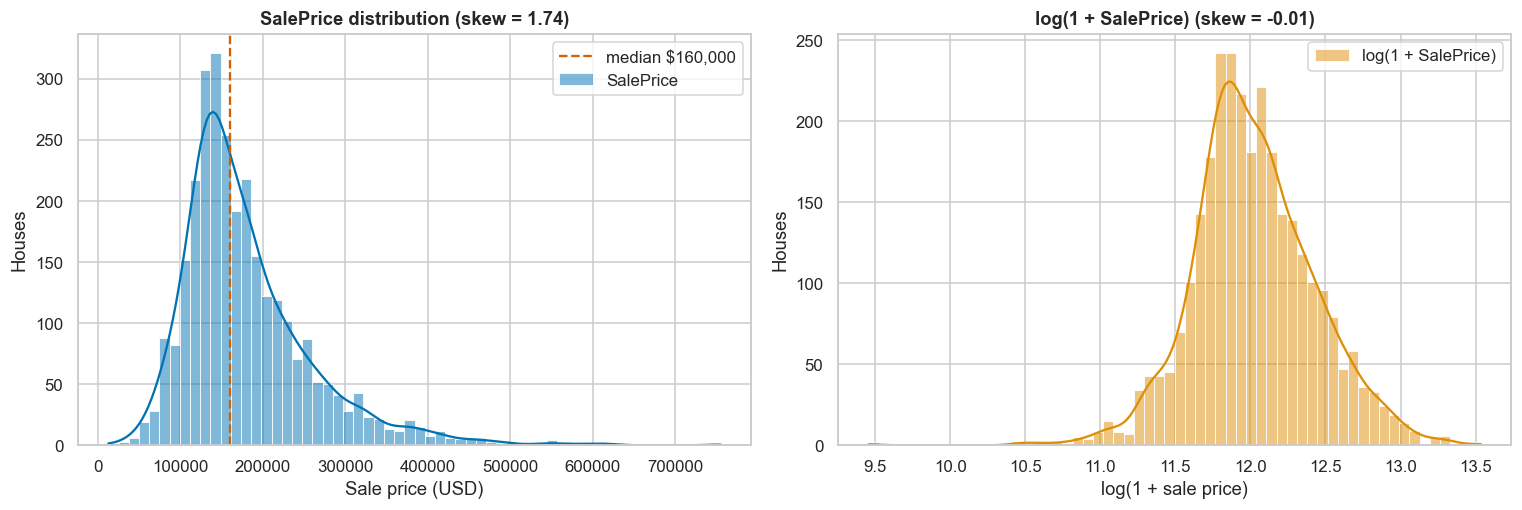

In [4]:
print(df['SalePrice'].describe().round(0).to_string())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(df['SalePrice'], bins=60, kde=True, ax=axes[0], color=PALETTE[0], label='SalePrice')
axes[0].axvline(df['SalePrice'].median(), color=PALETTE[3], ls='--', label=f"median ${df['SalePrice'].median():,.0f}")
axes[0].set(title=f"SalePrice distribution (skew = {df['SalePrice'].skew():.2f})", xlabel='Sale price (USD)', ylabel='Houses')
sns.histplot(np.log1p(df['SalePrice']), bins=60, kde=True, ax=axes[1], color=PALETTE[1], label='log(1 + SalePrice)')
axes[1].set(title=f"log(1 + SalePrice) (skew = {np.log1p(df['SalePrice']).skew():.2f})", xlabel='log(1 + sale price)', ylabel='Houses')
for ax in axes:
    ax.legend()
plt.tight_layout(); save_fig(fig, 'target_distribution'); plt.show()

**📝 Observations — audit and target**
- 2,930 sales × 82 columns (43 text, 39 numeric) with **no duplicate rows**. 27 columns have missing values. The worst, `Pool QC` (99.6 %), `Misc Feature`, `Alley` and `Fence`, are missing because the house simply *has no* pool/alley/fence. Missingness is therefore informative and is encoded as `'None'` rather than dropped.
- `SalePrice` ranges from \$12,789 to \$755,000 with median \$160,000 below the mean \$180,796: it is **right-skewed**. A few luxury homes would dominate squared-error losses.
- `log(1 + SalePrice)` is nearly symmetric. This motivates modelling the log of the price (§3.4): errors then become *relative* (10 % off a \$100k house counts like 10 % off a \$400k house).

---
## 2 · Exploratory data analysis

In [5]:
df_eda = df.drop(columns=['Order', 'PID'])
num_cols = [c for c in df_eda.select_dtypes('number').columns if c != 'SalePrice']
cat_cols = df_eda.select_dtypes(exclude='number').columns.tolist()
print(f'Numerical features: {len(num_cols)} | categorical features: {len(cat_cols)}')

Numerical features: 36 | categorical features: 43


### 2.1 Distribution of every numerical feature

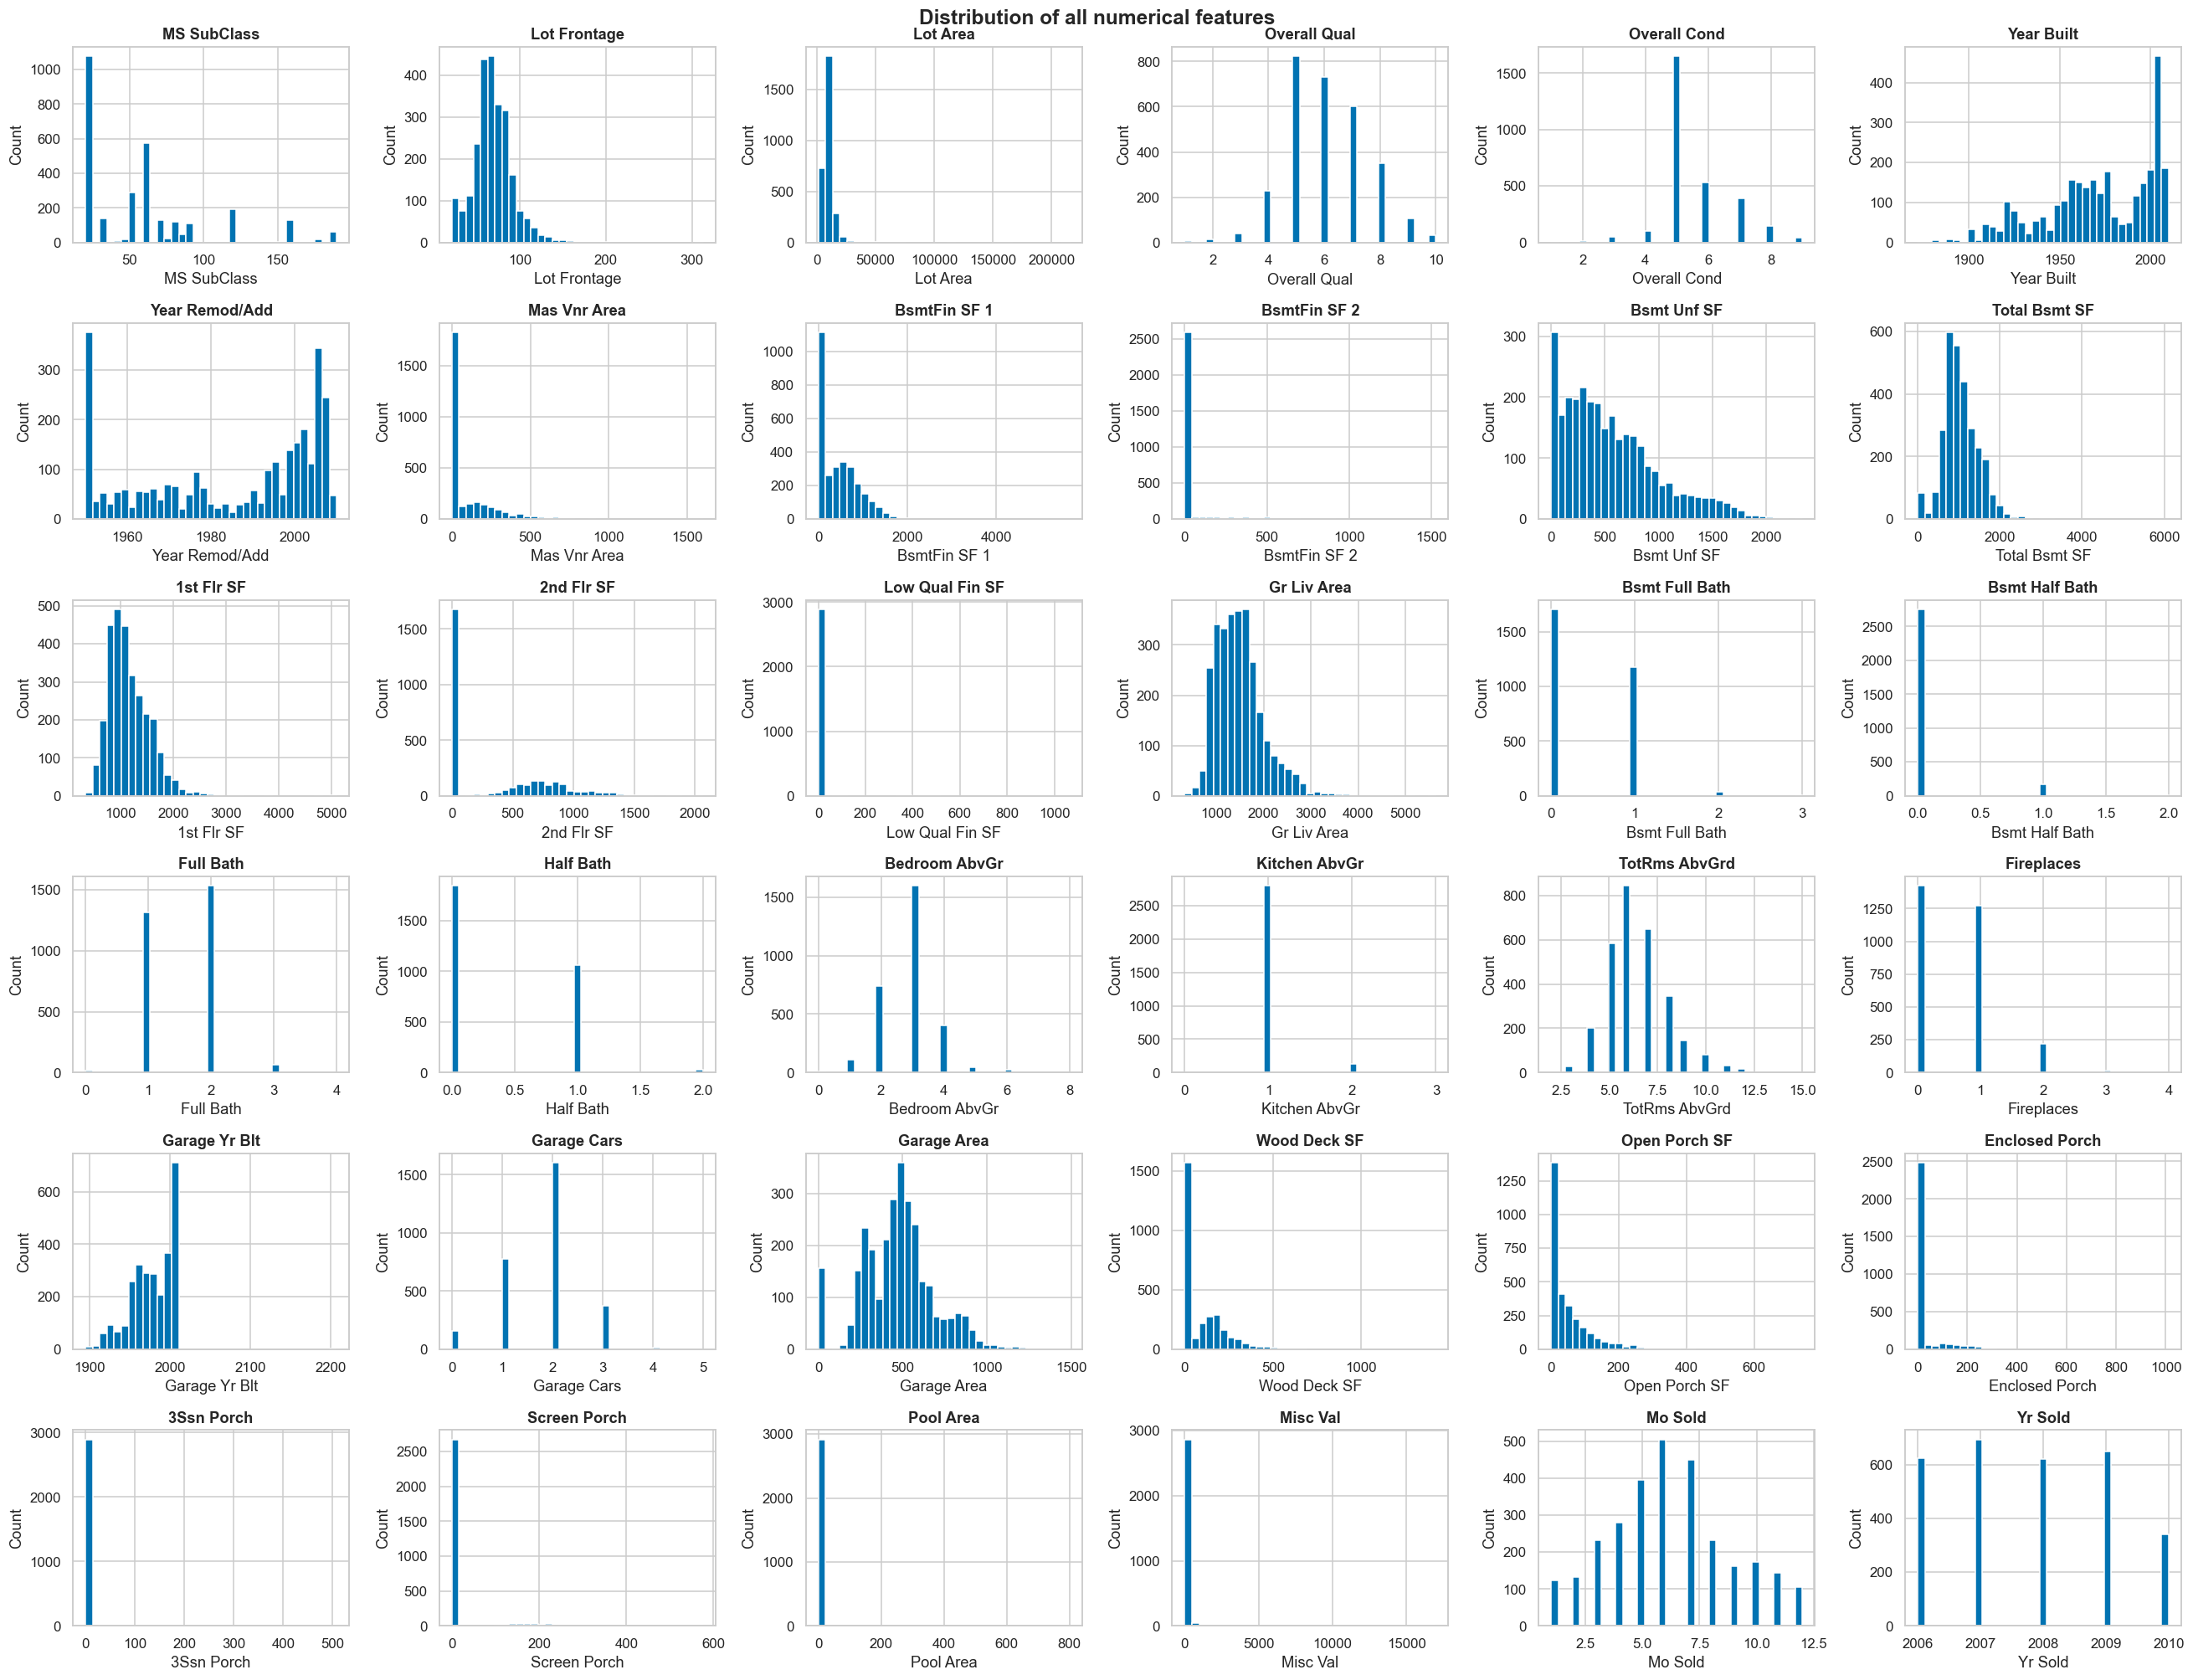

Most skewed features: {'Misc Val': 22.0, 'Pool Area': 16.9, 'Lot Area': 12.8, 'Low Qual Fin SF': 12.1, '3Ssn Porch': 11.4, 'Kitchen AbvGr': 4.3, 'BsmtFin SF 2': 4.1, 'Enclosed Porch': 4.0}


In [6]:
ncols = 6
nrows = int(np.ceil(len(num_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(24, nrows * 3.1))
for ax, col in zip(axes.flat, num_cols):
    ax.hist(df_eda[col].dropna(), bins=35, color=PALETTE[0], edgecolor='white', label=col)
    ax.set(title=col, xlabel=col, ylabel='Count')
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle('Distribution of all numerical features', fontsize=16, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'numerical_distributions'); plt.show()
print('Most skewed features:', df_eda[num_cols].skew().abs().sort_values(ascending=False).head(8).round(1).to_dict())

**📝 Observations — numerical distributions**
- Area features (`Lot Area`, `Gr Liv Area`, `Total Bsmt SF`) are right-skewed. `Misc Val`, `Pool Area`, `Low Qual Fin SF` and `3Ssn Porch` are almost always 0 (skewness 11–22). These zero-inflated columns carry little information except "present / absent", which is why `HasPool` was engineered.
- `Overall Qual` and `Overall Cond` are discrete 1–10 ratings centred on 5–6. `Year Built` has a long left tail of pre-1950 houses and a peak of new builds in the 2000s.
- `MS SubClass` is numeric only by storage: it is a dwelling-type **code**, so it is one-hot encoded.

### 2.2 Distribution of every categorical feature

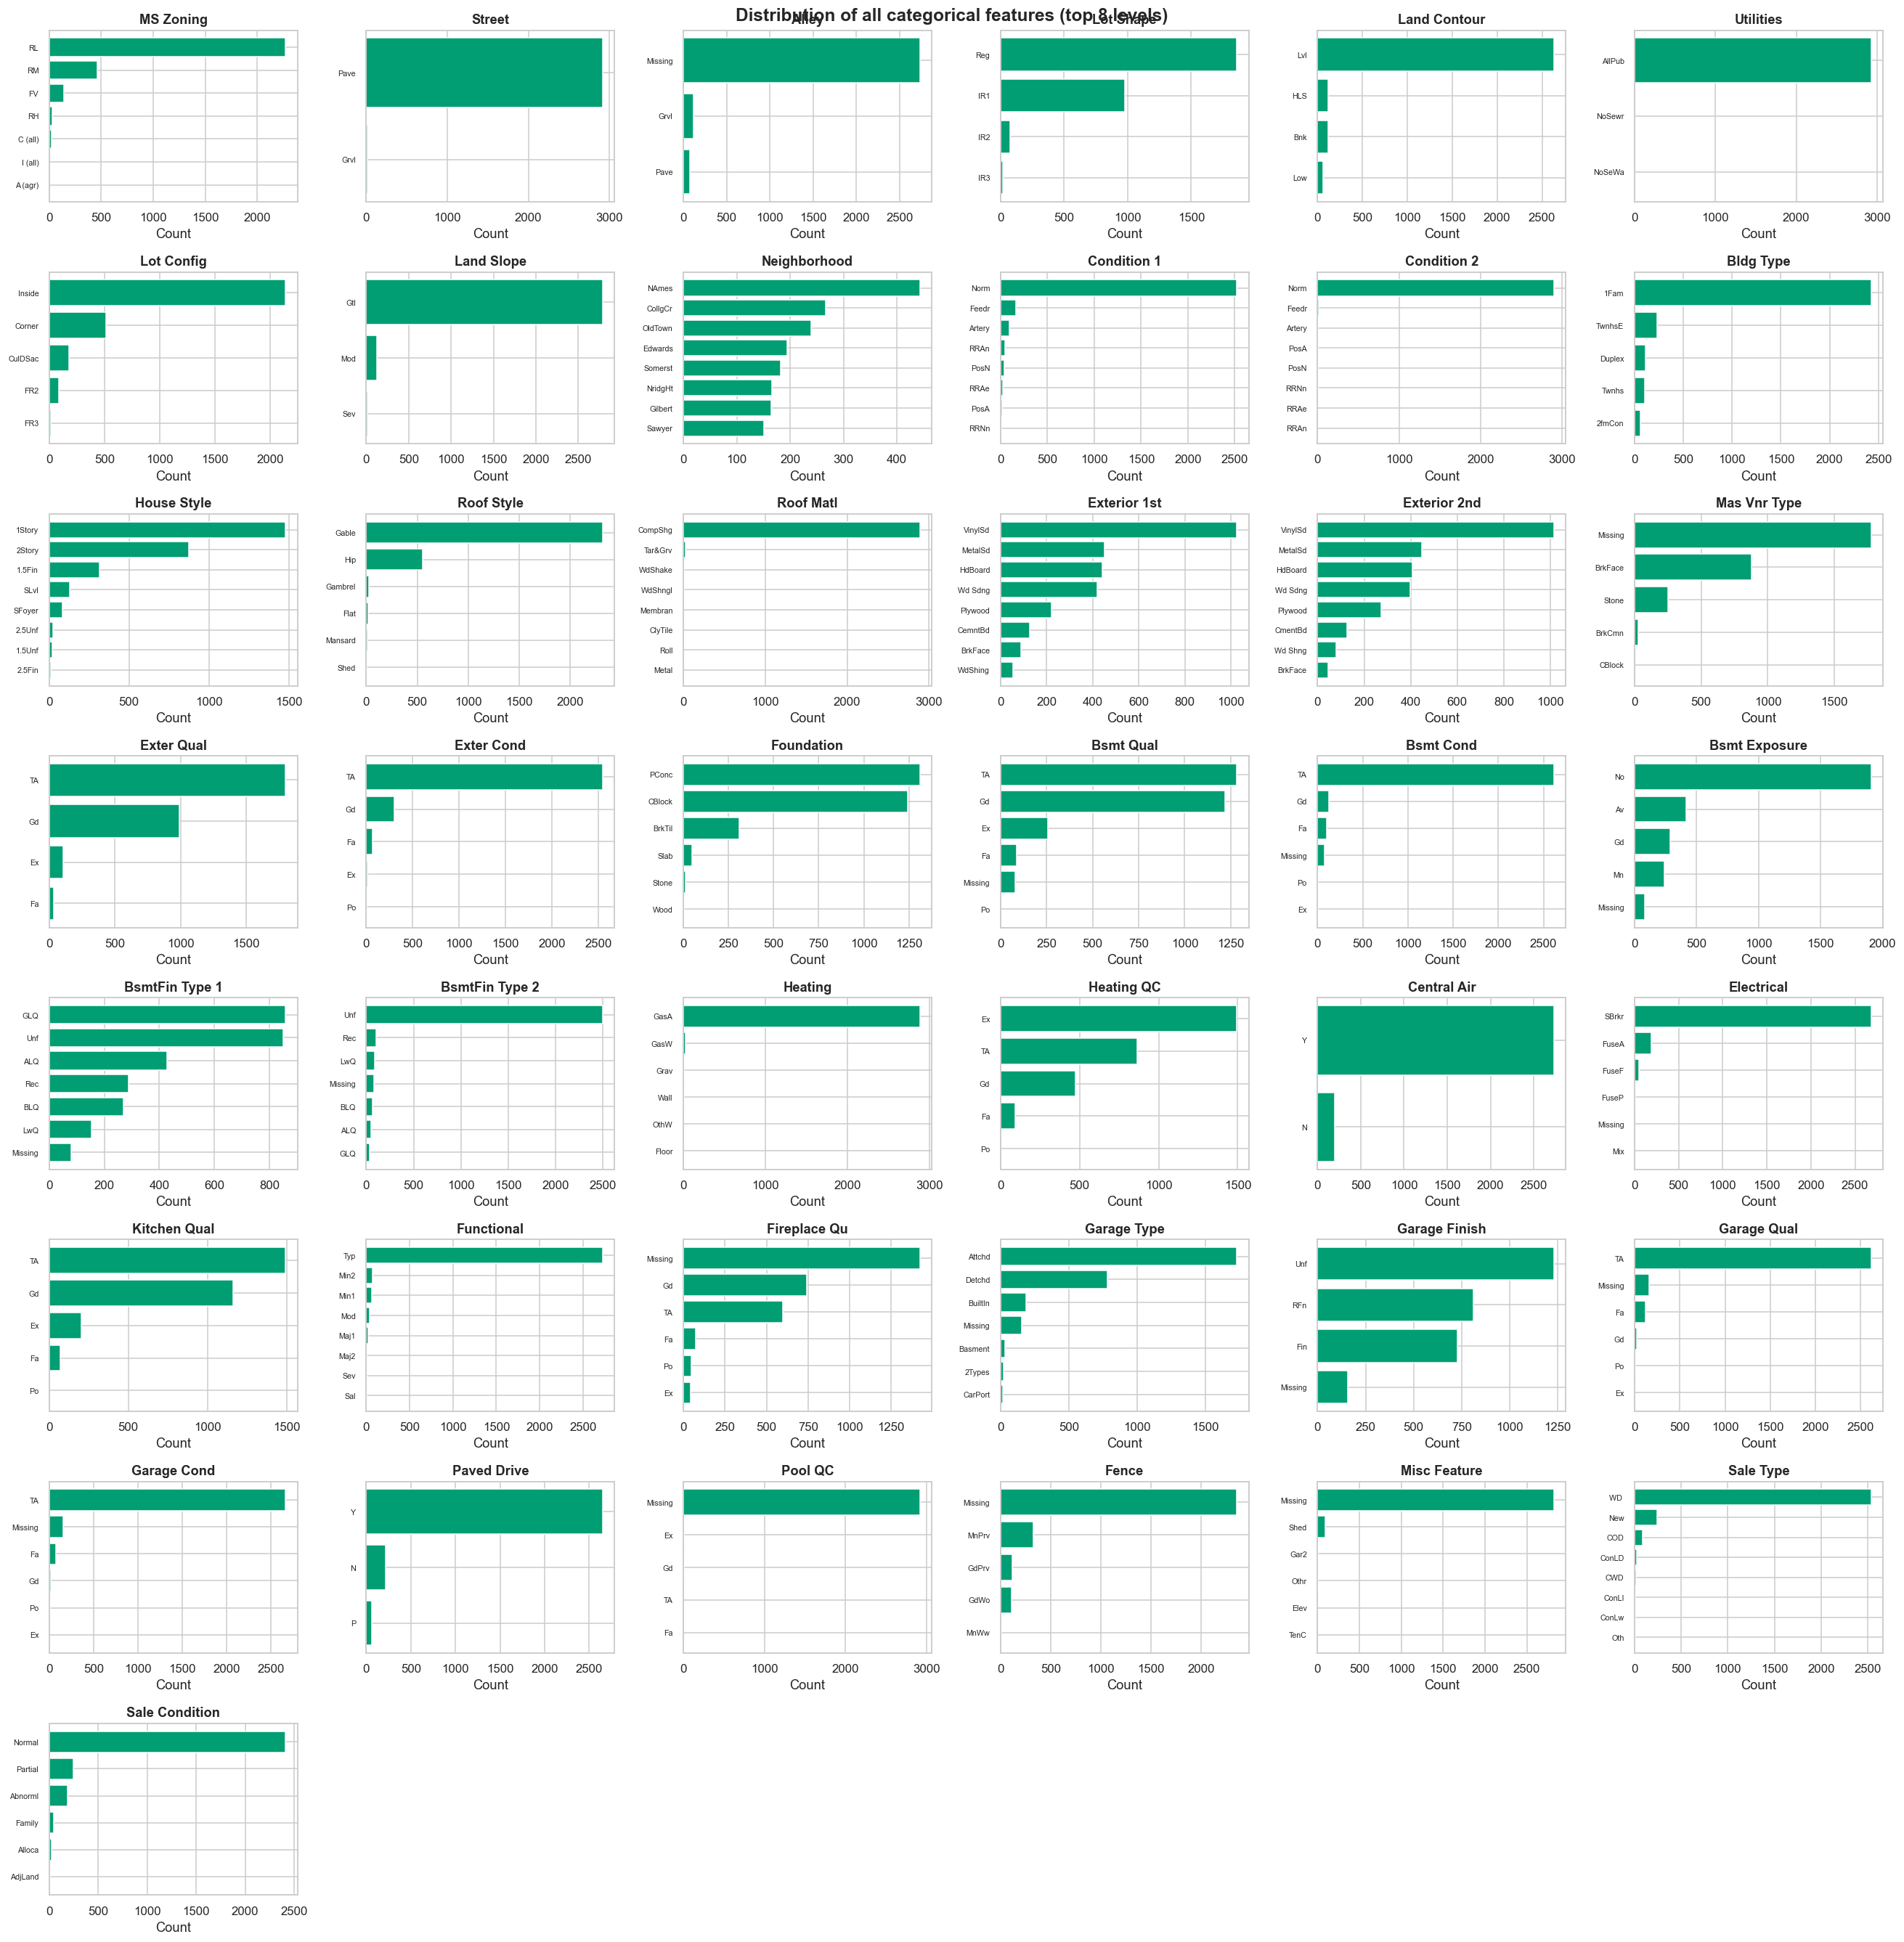

Categorical features dominated by one level (> 95 %): {'Utilities': 99.9, 'Street': 99.6, 'Pool QC': 99.6, 'Condition 2': 99.0, 'Roof Matl': 98.5, 'Heating': 98.5, 'Misc Feature': 96.4, 'Land Slope': 95.2}


In [7]:
ncols = 6
nrows = int(np.ceil(len(cat_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(24, nrows * 3.1))
for ax, col in zip(axes.flat, cat_cols):
    vc = df_eda[col].fillna('Missing').value_counts().head(8)
    ax.barh(vc.index.astype(str)[::-1], vc.values[::-1], color=PALETTE[2])
    ax.set(title=col, xlabel='Count', ylabel='')
    ax.tick_params(axis='y', labelsize=7)
for ax in axes.flat[len(cat_cols):]:
    ax.set_visible(False)
fig.suptitle('Distribution of all categorical features (top 8 levels)', fontsize=16, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'categorical_distributions'); plt.show()
dominant = (df_eda[cat_cols].apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0]) * 100).sort_values(ascending=False)
print('Categorical features dominated by one level (> 95 %):', dominant[dominant > 95].round(1).to_dict())

**📝 Observations — categorical distributions**
- Eight columns are dominated by one level (> 95 %): `Utilities` (99.9 % AllPub), `Street`, `Pool QC`, `Condition 2`, `Roof Matl`, `Heating`, `Misc Feature`, `Land Slope`. They barely vary, so one-hot encoding groups their rare levels as *infrequent* instead of creating many near-empty columns.
- `Neighborhood` has 28 levels with clear differences in volume and price (§2.5).
- The quality/condition columns (`Exter Qual`, `Kitchen Qual`, `Bsmt Qual`, …) use an ordered Po < Fa < TA < Gd < Ex scale, so they are **ordinal-encoded** to keep that order.

### 2.3 Correlation heatmap (20 features most correlated with SalePrice)

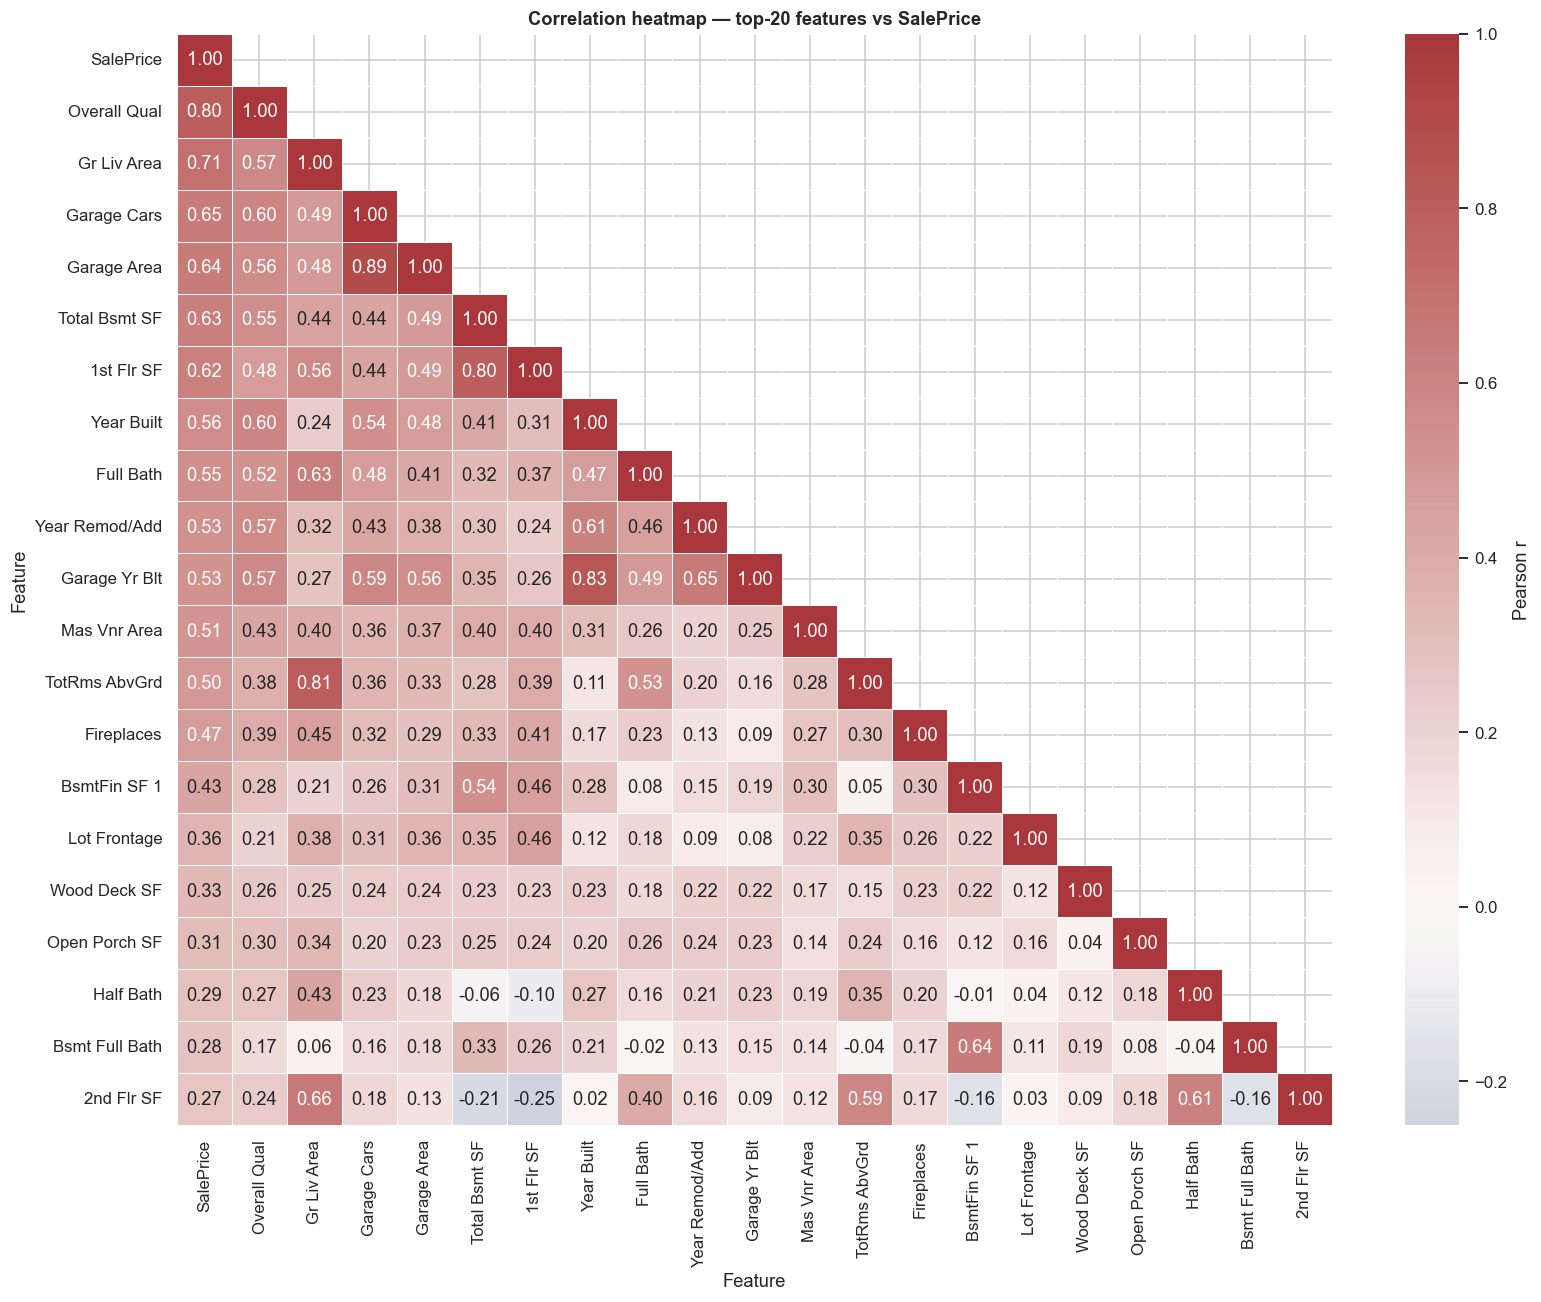

Overall Qual      0.799
Gr Liv Area       0.707
Garage Cars       0.648
Garage Area       0.640
Total Bsmt SF     0.632
1st Flr SF        0.622
Year Built        0.558
Full Bath         0.546
Year Remod/Add    0.533
Garage Yr Blt     0.527


In [8]:
corr = df_eda[num_cols + ['SalePrice']].corr()
top = corr['SalePrice'].abs().sort_values(ascending=False).head(21).index
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr.loc[top, top], mask=np.triu(np.ones((21, 21), dtype=bool), k=1), annot=True, fmt='.2f',
            cmap='vlag', center=0, linewidths=0.4, cbar_kws={'label': 'Pearson r'}, ax=ax)
ax.set(title='Correlation heatmap — top-20 features vs SalePrice', xlabel='Feature', ylabel='Feature')
plt.tight_layout(); save_fig(fig, 'correlation_heatmap'); plt.show()
print(corr['SalePrice'].drop('SalePrice').sort_values(ascending=False).head(10).round(3).to_string())

**📝 Observations — correlation heatmap**
- `Overall Qual` is the strongest single predictor (**r = 0.80**), followed by living area `Gr Liv Area` (0.71), garage size (`Garage Cars` 0.65, `Garage Area` 0.64), basement area (0.63) and `1st Flr SF` (0.62).
- There is strong **multicollinearity** among related pairs: `Garage Cars`↔`Garage Area`, `Total Bsmt SF`↔`1st Flr SF`, `Year Built`↔`Garage Yr Blt`. This can make plain linear-regression coefficients unstable, which is what Ridge, Lasso and ElasticNet regularisation are designed to handle.

### 2.4 Feature–target scatter plots

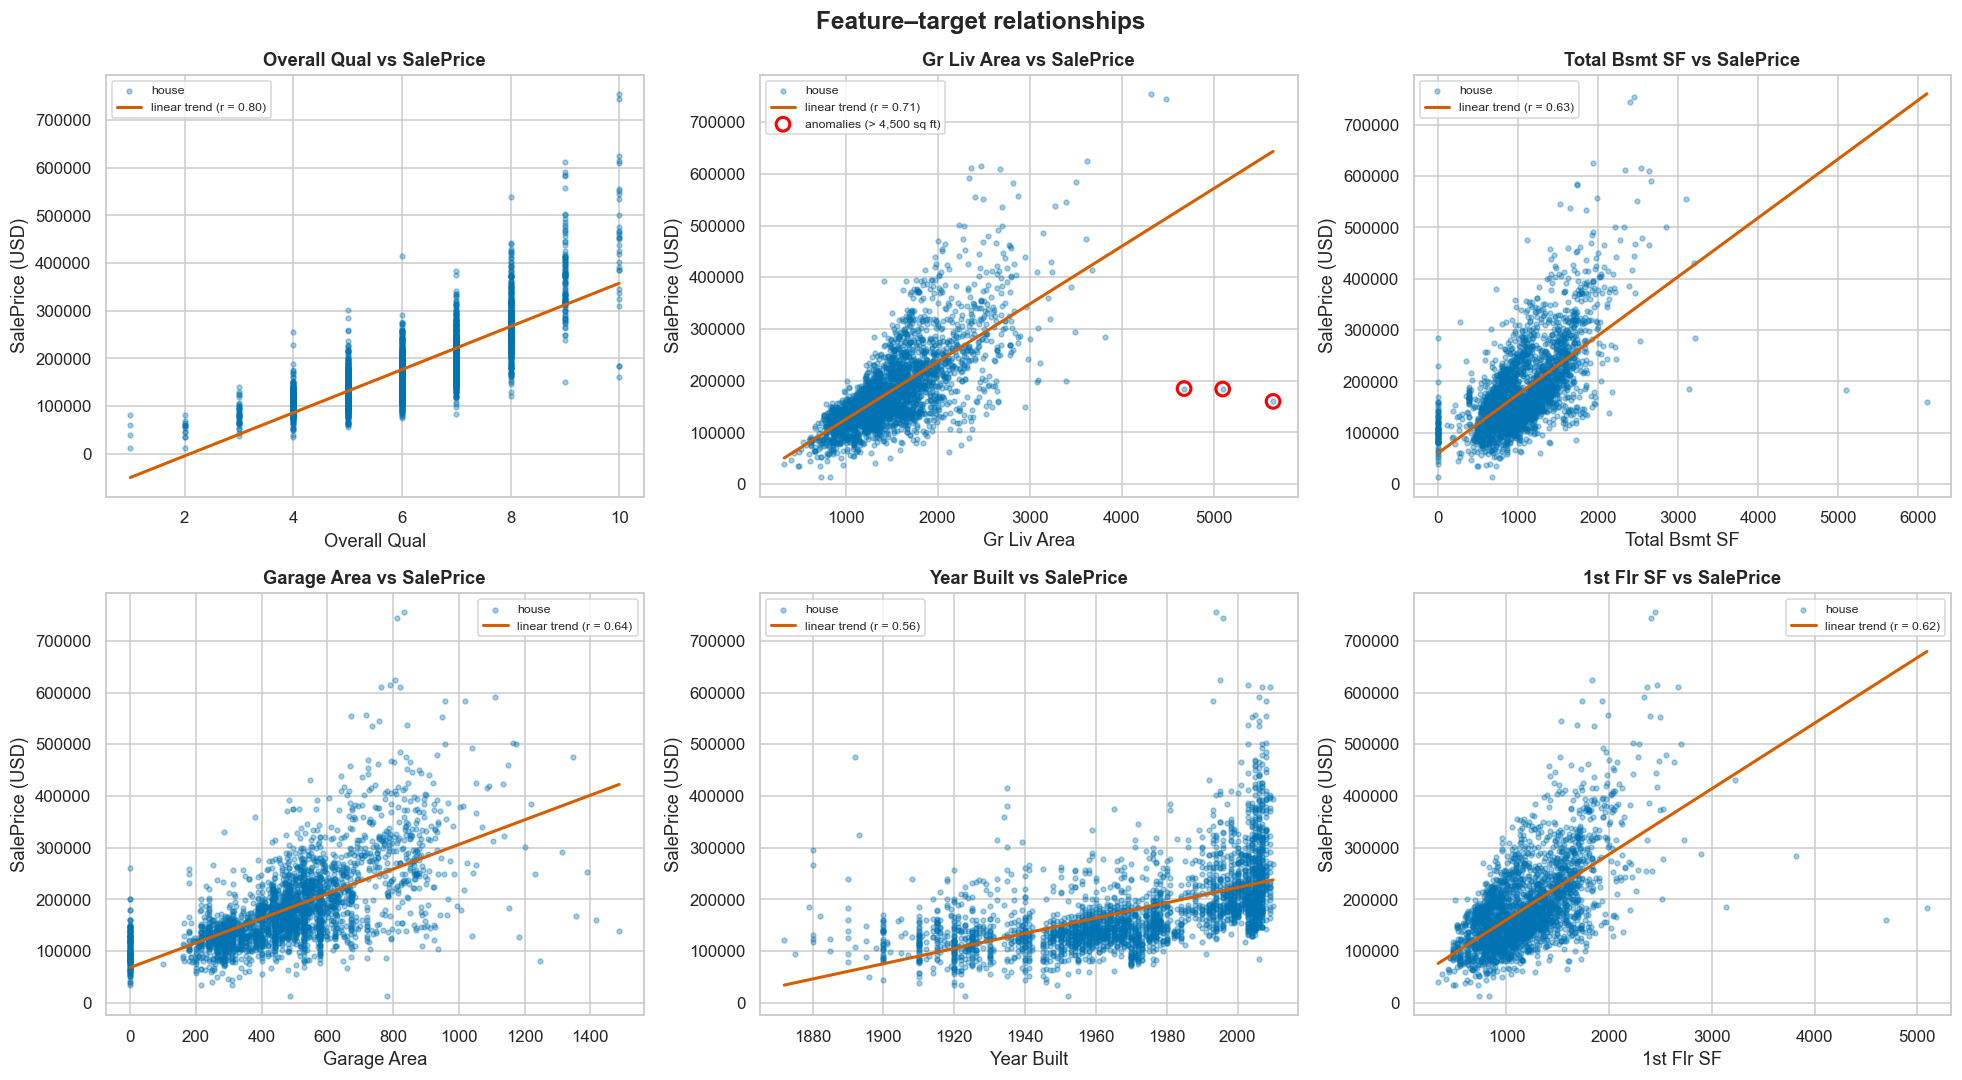

In [9]:
feats = ['Overall Qual', 'Gr Liv Area', 'Total Bsmt SF', 'Garage Area', 'Year Built', '1st Flr SF']
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, f in zip(axes.flat, feats):
    ok = df_eda[[f, 'SalePrice']].dropna()
    ax.scatter(ok[f], ok['SalePrice'], s=10, alpha=0.35, color=PALETTE[0], label='house')
    coef = np.polyfit(ok[f], ok['SalePrice'], 1)
    xs = np.linspace(ok[f].min(), ok[f].max(), 100)
    ax.plot(xs, np.polyval(coef, xs), color=PALETTE[3], lw=2, label=f'linear trend (r = {ok[f].corr(ok["SalePrice"]):.2f})')
    ax.set(title=f'{f} vs SalePrice', xlabel=f, ylabel='SalePrice (USD)')
    ax.legend(fontsize=8)
big = df_eda[df_eda['Gr Liv Area'] > 4500]
axes[0, 1].scatter(big['Gr Liv Area'], big['SalePrice'], s=80, facecolor='none', edgecolor='red', lw=2,
                   label='anomalies (> 4,500 sq ft)')
axes[0, 1].legend(fontsize=8)
fig.suptitle('Feature–target relationships', fontsize=16, fontweight='bold')
plt.tight_layout(); save_fig(fig, 'feature_target_scatter'); plt.show()

**📝 Observations — feature–target scatter plots**
- `Overall Qual` shows a steep, slightly **convex** relationship: each extra quality point is worth more at the top of the scale. Modelling log-price makes this closer to linear.
- `Gr Liv Area` is strongly linear, **except for the circled houses above 4,500 sq ft that sold far below the trend**. These are the partial sales documented by the dataset's author (De Cock, 2011) and are removed in §3.1.
- Basement and first-floor area show linear trends with a vertical stack at 0 (houses without a basement). Garage area and year built show positive but noisier relationships.

### 2.5 SalePrice by neighbourhood

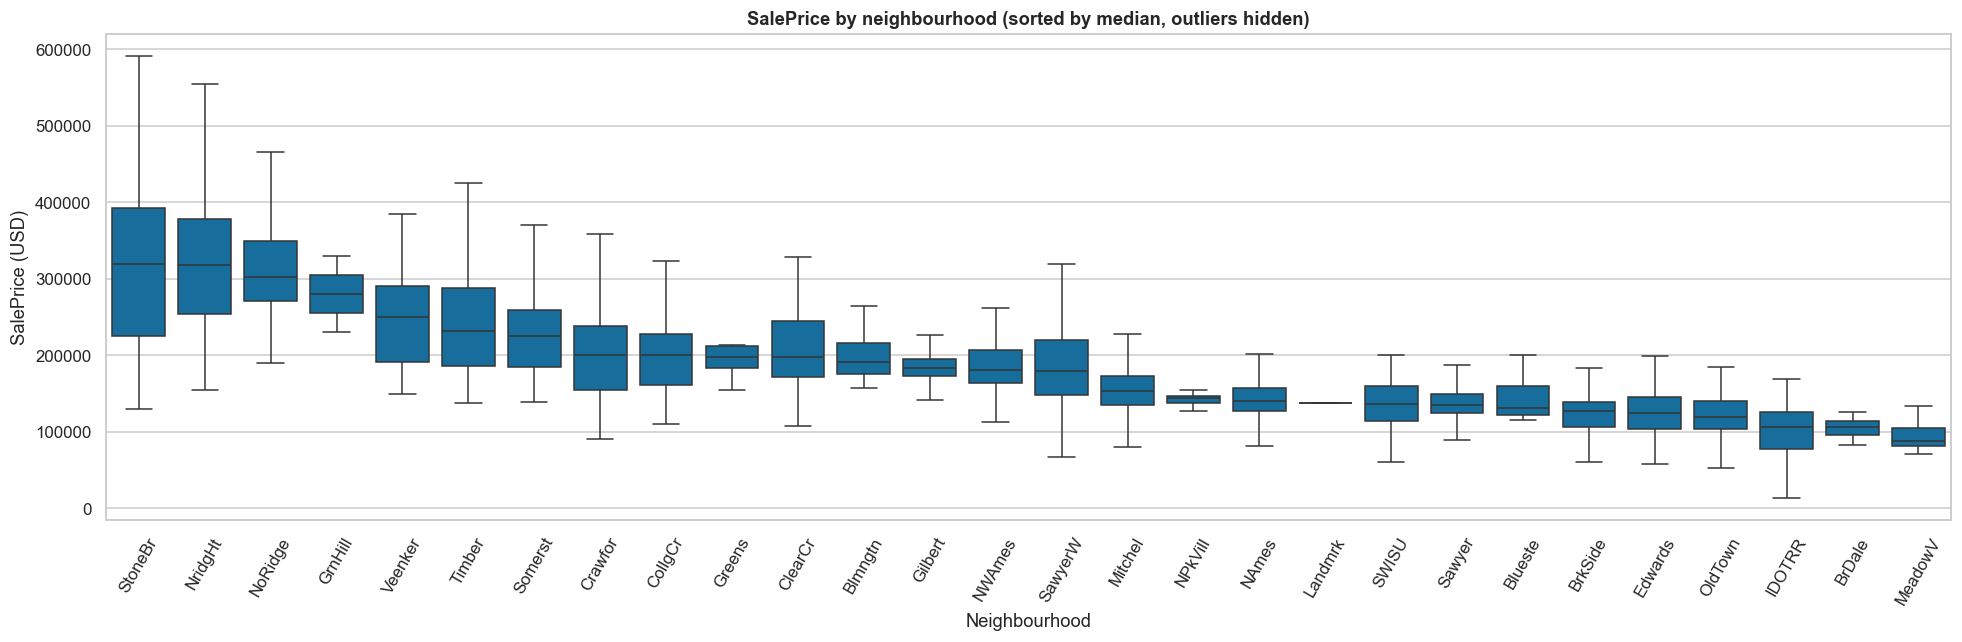

Most expensive: StoneBr ($319,000) | cheapest: MeadowV ($88,250) | ratio 3.6×


In [10]:
order = df_eda.groupby('Neighborhood')['SalePrice'].median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(18, 6))
sns.boxplot(data=df_eda, x='Neighborhood', y='SalePrice', order=order, color=PALETTE[0], ax=ax, showfliers=False)
ax.set(title='SalePrice by neighbourhood (sorted by median, outliers hidden)', xlabel='Neighbourhood', ylabel='SalePrice (USD)')
ax.tick_params(axis='x', rotation=60)
plt.tight_layout(); save_fig(fig, 'neighbourhood_boxplot'); plt.show()
med = df_eda.groupby('Neighborhood')['SalePrice'].median()
print(f'Most expensive: {med.idxmax()} (${med.max():,.0f}) | cheapest: {med.idxmin()} (${med.min():,.0f}) | ratio {med.max() / med.min():.1f}×')

**📝 Observations — neighbourhood**
- The median price in the most expensive neighbourhood (**StoneBr, \$319,000**) is **3.6×** that of the cheapest (**MeadowV, \$88,250**). Location explains price differences that size and quality alone cannot.
- With 28 unordered levels, `Neighborhood` is **one-hot encoded**, so each area gets its own price adjustment.

---
## 3 · Cleaning, feature engineering, encoding & splitting

> All learned preprocessing (imputation medians, encoders, scaler) lives in **one `ColumnTransformer` fitted on the
> training split only** (guideline 7.1).

### 3.1 Identifiers, duplicates and outliers

In [11]:
data = df.drop(columns=['Order', 'PID'])               # identifiers carry no information
print(f'Duplicate rows: {data.duplicated().sum()}')

q1, q3 = data['SalePrice'].quantile([0.25, 0.75])
lo, hi = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
n0 = len(data)
data = data[data['SalePrice'].between(lo, hi)]
n1 = len(data)
data = data[data['Gr Liv Area'] < 4500].reset_index(drop=True)   # documented partial-sale anomalies (De Cock, 2011)
print(f'SalePrice outside 3×IQR [{lo:,.0f}, {hi:,.0f}] removed: {n0 - n1}')
print(f'Gr Liv Area > 4,500 sq ft removed            : {n1 - len(data)}')
print(f'Rows remaining: {len(data):,}')

Duplicate rows: 0
SalePrice outside 3×IQR [-122,500, 465,500] removed: 26
Gr Liv Area > 4,500 sq ft removed            : 3
Rows remaining: 2,901


**📝 Observations — cleaning**
- No duplicates and no identifier information (`Order`, `PID` are dropped).
- **26 sales** are removed with an extreme-value rule on `SalePrice` (outside Q1 − 3·IQR … Q3 + 3·IQR, i.e. above \$465,500). 3×IQR is deliberately lenient: only truly extreme luxury sales are excluded.
- **3 more sales** with `Gr Liv Area` > 4,500 sq ft are removed (the anomalies circled in §2.4).
- 2,901 houses (99 %) remain. Outlier removal is applied before the split, but it uses only per-row values and a fixed rule, so it does not leak test information into training.

### 3.2 Feature engineering

| Feature | Formula | Justification |
|---------|---------|---------------|
| `TotalSF` | Total Bsmt SF + 1st Flr SF + 2nd Flr SF | buyers price the *total* usable space, not each floor separately |
| `HouseAge` | Yr Sold − Year Built | depreciation is driven by age at the time of sale |
| `RemodAge` | Yr Sold − Year Remod/Add | a recent renovation adds value |
| `TotalBath` | Full + ½·Half + Bsmt Full + ½·Bsmt Half | one convenience measure instead of four collinear counts |
| `HasPool` | Pool Area > 0 | `Pool Area` is 0 for 99.6 % of homes — presence is the usable signal |
| `HasGarage` | Garage Area > 0 | separates "no garage" from "small garage" |

In [12]:
def engineer_housing_features(frame):
    """Add the six engineered features (row-wise arithmetic only → no leakage)."""
    out = frame.copy()
    out['TotalSF'] = out['Total Bsmt SF'].fillna(0) + out['1st Flr SF'] + out['2nd Flr SF']
    out['HouseAge'] = out['Yr Sold'] - out['Year Built']
    out['RemodAge'] = out['Yr Sold'] - out['Year Remod/Add']
    out['TotalBath'] = (out['Full Bath'] + 0.5 * out['Half Bath']
                        + out['Bsmt Full Bath'].fillna(0) + 0.5 * out['Bsmt Half Bath'].fillna(0))
    out['HasPool'] = (out['Pool Area'] > 0).astype(int)
    out['HasGarage'] = (out['Garage Area'].fillna(0) > 0).astype(int)
    return out


data = engineer_housing_features(data)
ENGINEERED = ['TotalSF', 'HouseAge', 'RemodAge', 'TotalBath', 'HasPool', 'HasGarage']
display(pd.DataFrame({'corr_with_SalePrice': data[ENGINEERED].corrwith(data['SalePrice']).round(3),
                      'best_component_corr': [data[['Total Bsmt SF', '1st Flr SF', '2nd Flr SF']].corrwith(data['SalePrice']).max().round(3),
                                              data['Year Built'].corr(data['SalePrice']).round(3),
                                              data['Year Remod/Add'].corr(data['SalePrice']).round(3),
                                              data['Full Bath'].corr(data['SalePrice']).round(3),
                                              data['Pool Area'].corr(data['SalePrice']).round(3),
                                              data['Garage Area'].corr(data['SalePrice']).round(3)]},
                     index=ENGINEERED))

,corr_with_SalePrice,best_component_corr
TotalSF,0.816,0.635
HouseAge,-0.585,0.584
RemodAge,-0.557,0.556
TotalBath,0.640,0.552
HasPool,0.035,0.032
HasGarage,0.242,0.644


**📝 Observations — engineered features**
- **`TotalSF` is now the single strongest feature (r = 0.82)**, stronger than `Overall Qual` (0.80) and much stronger than any of its parts (best part 0.64). Buyers pay for total usable space.
- `TotalBath` (r = 0.64) beats `Full Bath` alone (0.55): half-baths and basement baths add value too.
- `HouseAge` (−0.59) and `RemodAge` (−0.56) carry the same information as the year columns but express it as *age at sale*, a more natural unit for depreciation.
- `HasGarage` (0.24) separates "no garage" from "small garage". `HasPool` is almost uninformative (0.04) because only a handful of houses (< 0.5 %) have a pool; regularised models will shrink it towards 0.

### 3.3 Train / test split (80 : 20)

In [13]:
TARGET = 'SalePrice'
X = data.drop(columns=[TARGET])
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f'Train: {len(X_train):,} rows | Test: {len(X_test):,} rows')
print(f'Mean SalePrice — train ${y_train.mean():,.0f} | test ${y_test.mean():,.0f}')

Train: 2,320 rows | Test: 581 rows
Mean SalePrice — train $177,226 | test $178,526


A plain random split is used because the target is continuous (*stratified* splitting applies to the classification
track). The near-identical train/test means show the split is representative.

### 3.4 Imputation, encoding and scaling

In [14]:
QUAL = ['Po', 'Fa', 'TA', 'Gd', 'Ex']
ORDINAL_MAPS = {
    'Exter Qual': QUAL, 'Exter Cond': QUAL, 'Heating QC': QUAL, 'Kitchen Qual': QUAL,
    'Bsmt Qual': ['None'] + QUAL, 'Bsmt Cond': ['None'] + QUAL, 'Fireplace Qu': ['None'] + QUAL,
    'Garage Qual': ['None'] + QUAL, 'Garage Cond': ['None'] + QUAL, 'Pool QC': ['None'] + QUAL,
    'BsmtFin Type 1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'BsmtFin Type 2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
    'Bsmt Exposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
    'Garage Finish': ['None', 'Unf', 'RFn', 'Fin'],
    'Land Slope': ['Sev', 'Mod', 'Gtl'],
    'Lot Shape': ['IR3', 'IR2', 'IR1', 'Reg'],
    'Functional': ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
    'Fence': ['None', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],
    'Paved Drive': ['N', 'P', 'Y'],            # Review-1 bug fixed here
}
ORDINAL = list(ORDINAL_MAPS)
NOMINAL = [c for c in X_train.select_dtypes(exclude='number').columns if c not in ORDINAL]
CODES = ['MS SubClass']                       # integer dwelling-type code → nominal, one-hot encoded
NUMERIC = [c for c in X_train.select_dtypes('number').columns if c not in CODES]


def build_preprocessor():
    """Unfitted ColumnTransformer; fitted on the training split only."""
    return ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUMERIC),
        ('ord', make_pipeline(SimpleImputer(strategy='constant', fill_value='None'),
                              OrdinalEncoder(categories=[ORDINAL_MAPS[c] for c in ORDINAL],
                                             handle_unknown='use_encoded_value', unknown_value=-1),
                              StandardScaler()), ORDINAL),
        ('nom', make_pipeline(SimpleImputer(strategy='constant', fill_value='None'),
                              OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20,
                                            sparse_output=False)), NOMINAL),
        ('code', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=20, sparse_output=False), CODES),
    ], verbose_feature_names_out=False).set_output(transform='pandas')


preprocessor = build_preprocessor().fit(X_train)       # fitted on TRAIN only
X_train_p = preprocessor.transform(X_train)
X_test_p = preprocessor.transform(X_test)
print(f'Numeric: {len(NUMERIC)} | ordinal: {len(ORDINAL)} | nominal (one-hot): {len(NOMINAL) + len(CODES)}')
print(f'Model-ready matrix — train {X_train_p.shape}, test {X_test_p.shape}; missing after imputation: '
      f'{int(X_train_p.isna().sum().sum()) + int(X_test_p.isna().sum().sum())}')

Numeric: 41 | ordinal: 19 | nominal (one-hot): 25
Model-ready matrix — train (2320, 202), test (581, 202); missing after imputation: 0


**Preprocessing summary**

| Step | Strategy | Justification |
|------|----------|---------------|
| Categorical NaN | constant `'None'` | in Ames a missing pool/garage/basement field means *the house has none* |
| Numerical NaN | training-set median | robust to skew; no information from the test split |
| Outliers | 3×IQR on `SalePrice` + `Gr Liv Area` > 4,500 removed (29 rows) | extreme/partial sales distort every model |
| Ordinal quality scales | explicit ordered categories | keeps *Po < Fa < TA < Gd < Ex* information |
| Nominal categoricals | one-hot, levels with < 20 training rows grouped | no artificial order |
| Scaling | `StandardScaler` (train only) | required for Ridge/Lasso/ElasticNet, SVR, KNN; harmless for trees |
| Target | `log1p` inside `TransformedTargetRegressor`, predictions back-transformed with `expm1` | right-skewed target; errors become relative |

---
## 4 · Training the 10 regression models

`run_model()` fits a **baseline** (library defaults) and a **tuned** version (5-fold `GridSearchCV` on the training
split, scoring = R² in USD) of each algorithm, always wrapped in a `TransformedTargetRegressor` (log target), and
evaluates both on the same test split.

In [15]:
RESULTS, SEARCHES = {}, {}


def log_target(est):
    """Model log(1 + price); predictions are returned in USD."""
    return TransformedTargetRegressor(regressor=est, func=np.log1p, inverse_func=np.expm1)


def evaluate(name, model, stage, Xte=None):
    Xte = X_test_p if Xte is None else Xte
    pred = model.predict(Xte)
    row = {'Model': name, 'Stage': stage, 'R2': r2_score(y_test, pred),
           'RMSE': np.sqrt(mean_squared_error(y_test, pred)), 'MAE': mean_absolute_error(y_test, pred)}
    RESULTS[(name, stage)] = {**row, 'model': model, 'y_pred': pred}
    return row


def run_model(name, estimator, grid, Xtr=None, Xte=None):
    """Baseline vs GridSearchCV-tuned model (5-fold CV on the training split)."""
    Xtr = X_train_p if Xtr is None else Xtr
    base = log_target(clone(estimator)).fit(Xtr, y_train)
    rows = [evaluate(name, base, 'Baseline', Xte)]
    best = base
    if grid:
        t0 = time.time()
        grids = grid if isinstance(grid, list) else [grid]
        search = GridSearchCV(log_target(clone(estimator)),
                              [{f'regressor__{k}': v for k, v in g.items()} for g in grids],
                              scoring='r2', cv=CV5, n_jobs=-1).fit(Xtr, y_train)
        SEARCHES[name] = search
        best = search.best_estimator_
        params = fmt_params(search.best_params_, 'regressor__')
        print(f'{name}: {len(search.cv_results_["params"])} candidates in {time.time() - t0:.1f}s → {params} '
              f'(CV R² {search.best_score_:.4f})')
        rows.append(evaluate(name, best, 'Tuned', Xte))
    else:
        RESULTS[(name, 'Tuned')] = {**RESULTS[(name, 'Baseline')], 'Stage': 'Tuned'}
        print(f'{name}: no hyper-parameters to tune')
    display(pd.DataFrame(rows).set_index('Stage').drop(columns='Model')
            .style.format({'R2': '{:.4f}', 'RMSE': '${:,.0f}', 'MAE': '${:,.0f}'}))
    return best


def fmt_params(params, prefix=''):
    """Readable hyper-parameter dict: plain Python numbers, optional key prefix removed."""
    return {k.replace(prefix, ''): (float(f'{v:.4g}') if isinstance(v, (float, np.floating)) else v)
            for k, v in params.items()}


def curve(name, param):
    res = pd.DataFrame(SEARCHES[name].cv_results_)
    best = SEARCHES[name].best_params_
    mask = np.ones(len(res), dtype=bool)
    for k, v in best.items():
        if k != f'regressor__{param}':
            mask &= res[f'param_{k}'].astype(str) == str(v)
    return res.loc[mask, [f'param_regressor__{param}', 'mean_test_score', 'std_test_score']].rename(
        columns={f'param_regressor__{param}': param})

### 4.1 Linear Regression — baseline; interpret coefficients

Linear Regression: no hyper-parameters to tune


,R2,RMSE,MAE
Stage,,,
Baseline,0.9234,"$19,610","$12,909"


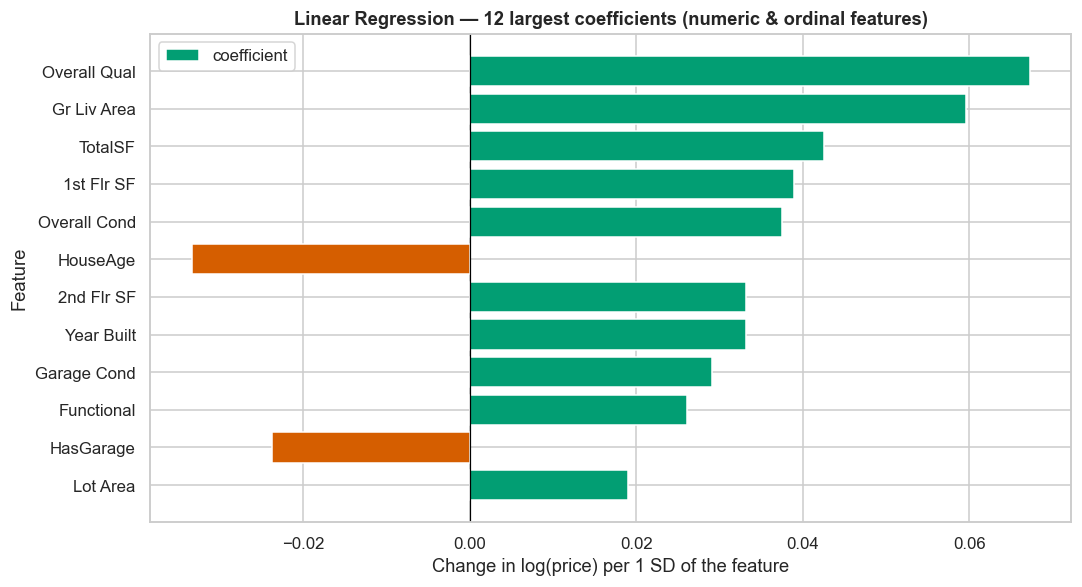

Interpretation: +1 SD of a feature multiplies the predicted price by exp(coef).
Overall Qual    +7.0%
Gr Liv Area     +6.1%
TotalSF         +4.3%
1st Flr SF      +4.0%
Overall Cond    +3.8%


In [16]:
lin = run_model('Linear Regression', LinearRegression(), None)
coef = pd.Series(lin.regressor_.coef_, index=X_train_p.columns)[NUMERIC + ORDINAL]   # standardised, interpretable columns
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(12)
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top.index[::-1], top.values[::-1], color=[PALETTE[2] if v > 0 else PALETTE[3] for v in top.values[::-1]],
        label='coefficient')
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Linear Regression — 12 largest coefficients (numeric & ordinal features)', xlabel='Change in log(price) per 1 SD of the feature',
       ylabel='Feature')
ax.legend()
plt.tight_layout(); save_fig(fig, 'linear_coefficients'); plt.show()
print('Interpretation: +1 SD of a feature multiplies the predicted price by exp(coef).')
print((np.exp(top.head(5)) - 1).map('{:+.1%}'.format).to_string())

**📝 Observations — Linear Regression**
- With the log target and the corrected encoding, plain OLS already reaches **test R² = 0.923 (RMSE \$19,610)**, against 0.898 in Review 1. Most of the improvement comes from modelling `log(price)` and from one-hot encoding the nominal columns.
- The coefficient chart shows *percentage* effects. Because the target is `log(price)`, a coefficient *b* means one standard deviation more of the feature multiplies the price by e^*b*. Overall quality (+7.0 % per SD), living area (+6.1 %) and total square footage (+4.3 %) have the largest effects, as expected from the EDA.
- OLS has no hyper-parameters; its weakness is unregularised coefficients on 202 correlated columns.

### 4.2 Ridge Regression — L2 regularisation; tune `alpha`

In [17]:
ridge = run_model('Ridge Regression', Ridge(), {'alpha': np.logspace(-2, 3, 11)})

Ridge Regression: 11 candidates in 8.4s → {'alpha': 31.62} (CV R² 0.9308)


,R2,RMSE,MAE
Stage,,,
Baseline,0.9228,"$19,677","$12,932"
Tuned,0.9275,"$19,075","$12,730"


### 4.3 Lasso Regression — L1 regularisation; feature sparsity

Lasso Regression: 9 candidates in 4.5s → {'alpha': 0.0003162} (CV R² 0.9317)


,R2,RMSE,MAE
Stage,,,
Baseline,-0.0415,"$72,291","$52,202"
Tuned,0.9313,"$18,572","$12,668"


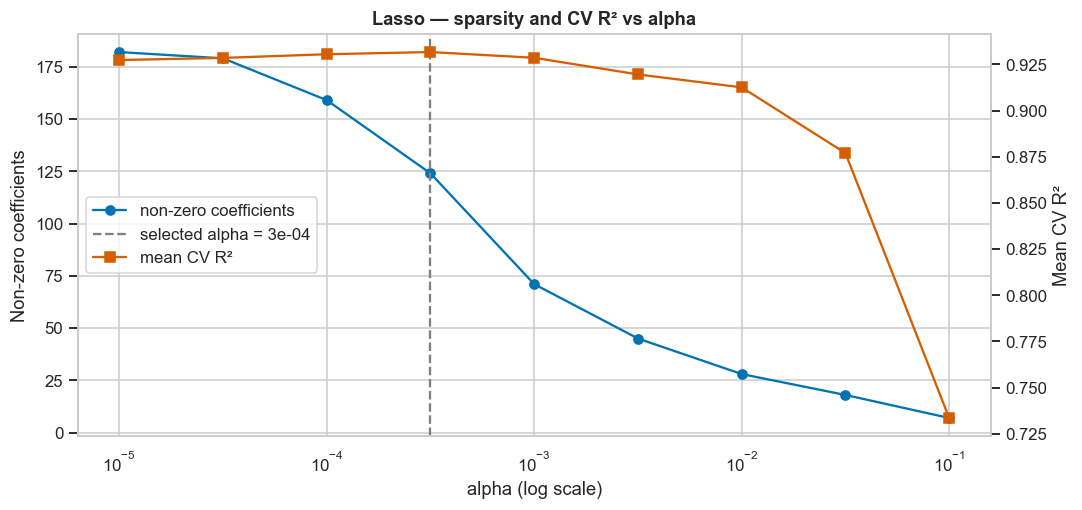

Tuned Lasso keeps 124 of 202 features (78 set exactly to 0)


In [18]:
lasso = run_model('Lasso Regression', Lasso(max_iter=20000), {'alpha': np.logspace(-5, -1, 9)})

alphas = np.logspace(-5, -1, 9)
nonzero = [(np.abs(log_target(Lasso(alpha=a, max_iter=20000)).fit(X_train_p, y_train).regressor_.coef_) > 0).sum()
           for a in alphas]
c = curve('Lasso Regression', 'alpha')
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.semilogx(alphas, nonzero, marker='o', color=PALETTE[0], label='non-zero coefficients')
ax.set(title='Lasso — sparsity and CV R² vs alpha', xlabel='alpha (log scale)', ylabel='Non-zero coefficients')
ax2 = ax.twinx(); ax2.grid(False)
ax2.semilogx(c['alpha'].astype(float), c['mean_test_score'], marker='s', color=PALETTE[3], label='mean CV R²')
ax2.set_ylabel('Mean CV R²')
best_a = SEARCHES['Lasso Regression'].best_params_['regressor__alpha']
ax.axvline(best_a, ls='--', color='grey', label=f'selected alpha = {best_a:.0e}')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='center left')
plt.tight_layout(); save_fig(fig, 'lasso_sparsity'); plt.show()
n_zero = int((lasso.regressor_.coef_ == 0).sum())
print(f'Tuned Lasso keeps {X_train_p.shape[1] - n_zero} of {X_train_p.shape[1]} features ({n_zero} set exactly to 0)')

### 4.4 ElasticNet — combined L1 + L2; tune `l1_ratio`

ElasticNet: 45 candidates in 22.9s → {'alpha': 0.001, 'l1_ratio': 0.3} (CV R² 0.9316)


,R2,RMSE,MAE
Stage,,,
Baseline,-0.0415,"$72,291","$52,202"
Tuned,0.9313,"$18,568","$12,660"


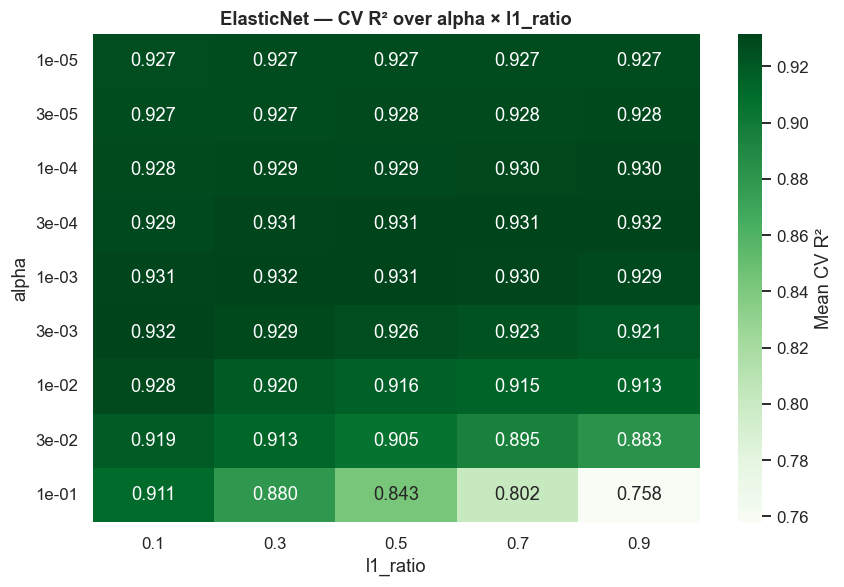

In [19]:
enet = run_model('ElasticNet', ElasticNet(max_iter=20000),
                 {'alpha': np.logspace(-5, -1, 9), 'l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]})
res = pd.DataFrame(SEARCHES['ElasticNet'].cv_results_)
heat = res.pivot_table(index='param_regressor__alpha', columns='param_regressor__l1_ratio', values='mean_test_score')
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.heatmap(heat, annot=True, fmt='.3f', cmap='Greens', cbar_kws={'label': 'Mean CV R²'}, ax=ax)
ax.set(title='ElasticNet — CV R² over alpha × l1_ratio', xlabel='l1_ratio', ylabel='alpha')
ax.set_yticklabels([f'{float(t.get_text()):.0e}' for t in ax.get_yticklabels()], rotation=0)
plt.tight_layout(); save_fig(fig, 'elasticnet_grid'); plt.show()

**📝 Observations — Ridge, Lasso and ElasticNet**
- **Ridge** (L2): CV chose `alpha ≈ 31.6`, improving test R² from 0.9228 to **0.9275**. Shrinking all coefficients reduces the variance caused by correlated features.
- **Lasso** (L1): with the library default `alpha = 1` every coefficient is set to zero, because on the log scale the penalty is far larger than any coefficient. The model predicts a constant (R² = −0.04). CV selects `alpha ≈ 3×10⁻⁴`, giving **R² = 0.9313**, and it **drops 78 of 202 features** (sets them exactly to 0). The sparsity chart shows the trade-off: as `alpha` grows, fewer features survive, and CV R² collapses once important ones are removed.
- **ElasticNet** (L1 + L2): best at `alpha = 0.001, l1_ratio = 0.3`, i.e. mostly Ridge-like with some Lasso selection. Test **R² = 0.9313, RMSE \$18,568**. The heatmap shows a broad high-scoring region for small `alpha` at every `l1_ratio`, so the choice of `alpha` matters far more than the L1/L2 mix.
- **Lesson:** default regularisation strengths are meaningless without tuning. They must be chosen relative to the scale of the target.

### 4.5 Polynomial Regression — `PolynomialFeatures` + Linear Regression; compare degrees
Expanding all 160+ columns would create >13,000 degree-2 terms for 2,320 houses, so the expansion is applied to the
**10 numerical features most correlated with price (selected on the training split only)**.

Polynomial input features: ['Overall Qual', 'TotalSF', 'Gr Liv Area', 'Garage Cars', 'TotalBath', 'Garage Area', 'Total Bsmt SF', 'HouseAge', 'Year Built', '1st Flr SF']


,n_terms,train R² (CV),validation R² (CV),test R²
degree,,,,
1,10,0.8747,0.8710,0.8732
2,65,0.8838,0.8671,0.8789
3,285,0.9071,-10269.0705,-470.8014


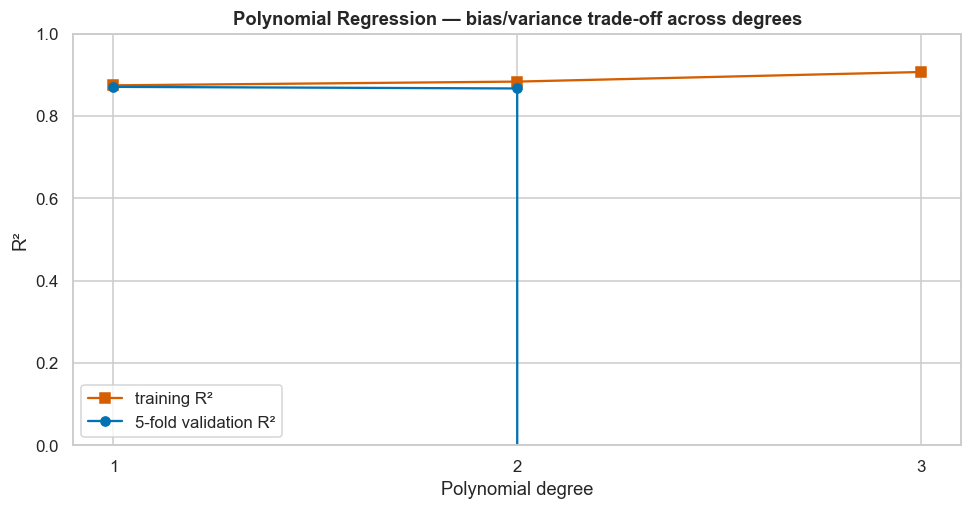

Selected degree (best CV R²): 1


In [20]:
corr_train = X_train_p[NUMERIC].corrwith(np.log1p(y_train)).abs().sort_values(ascending=False)
POLY_FEATS = corr_train.head(10).index.tolist()
print('Polynomial input features:', POLY_FEATS)

rows = []
for d in [1, 2, 3]:
    est = make_pipeline(PolynomialFeatures(degree=d, include_bias=False), LinearRegression())
    cv = cross_validate(log_target(est), X_train_p[POLY_FEATS], y_train, cv=CV5, scoring='r2',
                        return_train_score=True)
    fitted = log_target(est).fit(X_train_p[POLY_FEATS], y_train)
    rows.append({'degree': d, 'n_terms': fitted.regressor_[0].n_output_features_,
                 'train R² (CV)': cv['train_score'].mean(), 'validation R² (CV)': cv['test_score'].mean(),
                 'test R²': r2_score(y_test, fitted.predict(X_test_p[POLY_FEATS]))})
poly_tbl = pd.DataFrame(rows).set_index('degree')
display(poly_tbl.style.format({'train R² (CV)': '{:.4f}', 'validation R² (CV)': '{:.4f}', 'test R²': '{:.4f}'}))
BEST_DEG = int(poly_tbl['validation R² (CV)'].idxmax())

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(poly_tbl.index, poly_tbl['train R² (CV)'], marker='s', color=PALETTE[3], label='training R²')
ax.plot(poly_tbl.index, poly_tbl['validation R² (CV)'], marker='o', color=PALETTE[0], label='5-fold validation R²')
ax.set(title='Polynomial Regression — bias/variance trade-off across degrees', xlabel='Polynomial degree',
       ylabel='R²', xticks=[1, 2, 3], ylim=(max(0, poly_tbl[['train R² (CV)', 'validation R² (CV)']].min().min() - 0.05), 1))
ax.legend()
plt.tight_layout(); save_fig(fig, 'polynomial_degrees'); plt.show()

# Register degree 1 as baseline and the CV-selected degree as the tuned model
for stage, d in [('Baseline', 1), ('Tuned', BEST_DEG)]:
    m = log_target(make_pipeline(PolynomialFeatures(degree=d, include_bias=False), LinearRegression()))
    evaluate('Polynomial Regression', m.fit(X_train_p[POLY_FEATS], y_train), stage, X_test_p[POLY_FEATS])
print(f'Selected degree (best CV R²): {BEST_DEG}')

**📝 Observations — polynomial degrees**

| Degree | Terms | Train R² | CV R² | Diagnosis |
|--------|-------|----------|-------|-----------|
| 1 | 10 | 0.875 | **0.871** | best generalisation |
| 2 | 65 | 0.884 | 0.867 | small gain on train, small loss on CV → starting to over-fit |
| 3 | 285 | 0.907 | −10,269 | **severe over-fitting**: unregularised OLS on 285 highly collinear terms explodes on unseen folds |

- Training R² rises with every degree while validation R² falls. This is the bias–variance trade-off in its clearest form.
- CV therefore selects **degree 1**. On these 10 features, curvature adds less than the variance it costs. (Degree 2 is slightly better on this particular test split, 0.879 vs 0.873, but choosing on the test split would be leakage.)
- Polynomial regression is restricted to 10 features, so it scores below the full-feature linear models (0.873). Its value here is to demonstrate model-complexity control.

### 4.6 Decision Tree Regressor — tune `max_depth`; feature importance

Decision Tree: 32 candidates in 1.4s → {'max_depth': 10, 'min_samples_leaf': 10} (CV R² 0.8409)


,R2,RMSE,MAE
Stage,,,
Baseline,0.7931,"$32,223","$22,405"
Tuned,0.8430,"$28,067","$19,856"


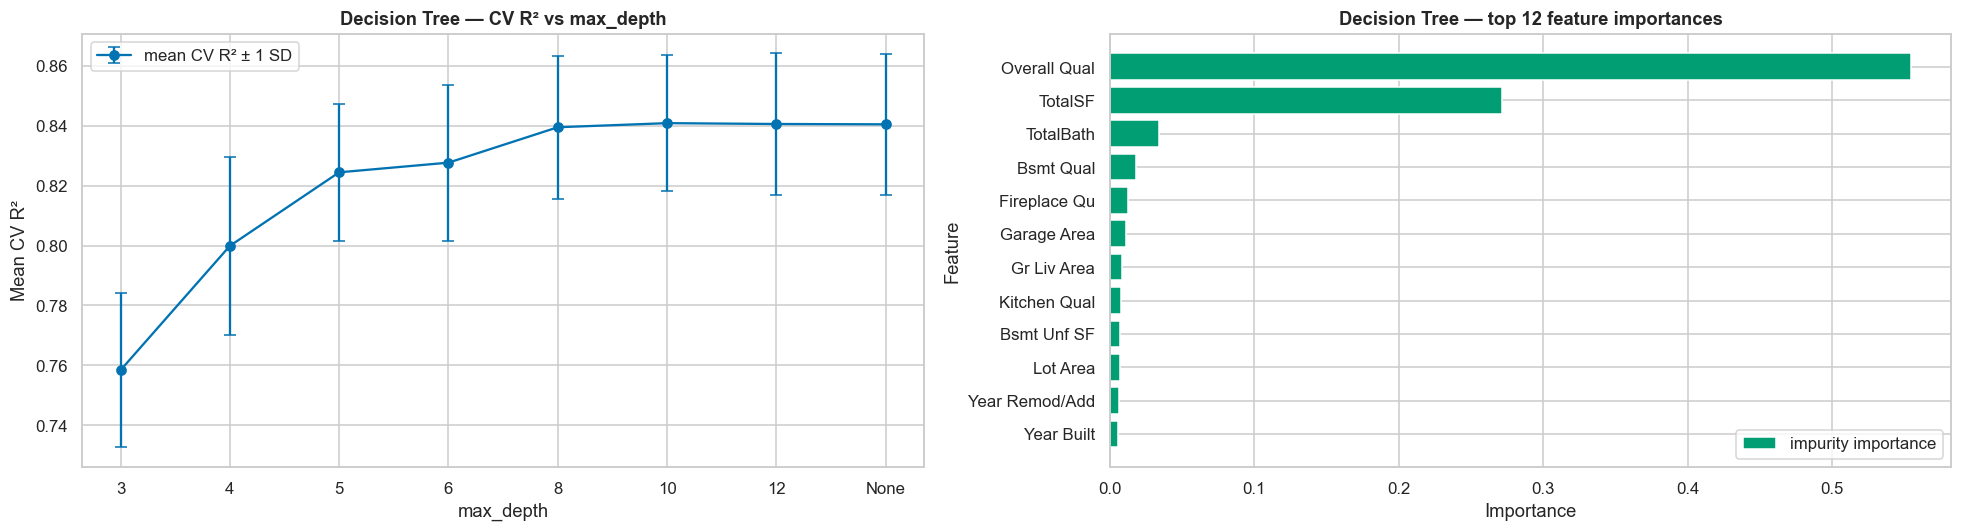

In [21]:
dt = run_model('Decision Tree', DecisionTreeRegressor(random_state=RANDOM_STATE),
               {'max_depth': [3, 4, 5, 6, 8, 10, 12, None], 'min_samples_leaf': [1, 5, 10, 20]})
c = curve('Decision Tree', 'max_depth')
imp = pd.Series(dt.regressor_.feature_importances_, index=X_train_p.columns).sort_values().tail(12)
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
pos = np.arange(len(c))
axes[0].errorbar(pos, c['mean_test_score'], yerr=c['std_test_score'], marker='o',
                 capsize=4, color=PALETTE[0], label='mean CV R² ± 1 SD')
axes[0].set_xticks(pos, ['None' if str(d) in ('None', 'nan') else str(int(float(d))) for d in c['max_depth']])
axes[0].set(title='Decision Tree — CV R² vs max_depth', xlabel='max_depth', ylabel='Mean CV R²')
axes[0].legend()
axes[1].barh(imp.index, imp.values, color=PALETTE[2], label='impurity importance')
axes[1].set(title='Decision Tree — top 12 feature importances', xlabel='Importance', ylabel='Feature')
axes[1].legend(loc='lower right')
plt.tight_layout(); save_fig(fig, 'decision_tree'); plt.show()

### 4.7 Random Forest Regressor — tune `n_estimators`

Random Forest: 18 candidates in 82.8s → {'max_depth': 20, 'max_features': 0.33, 'n_estimators': 400} (CV R² 0.9084)


,R2,RMSE,MAE
Stage,,,
Baseline,0.9120,"$21,008","$13,814"
Tuned,0.9215,"$19,849","$12,916"


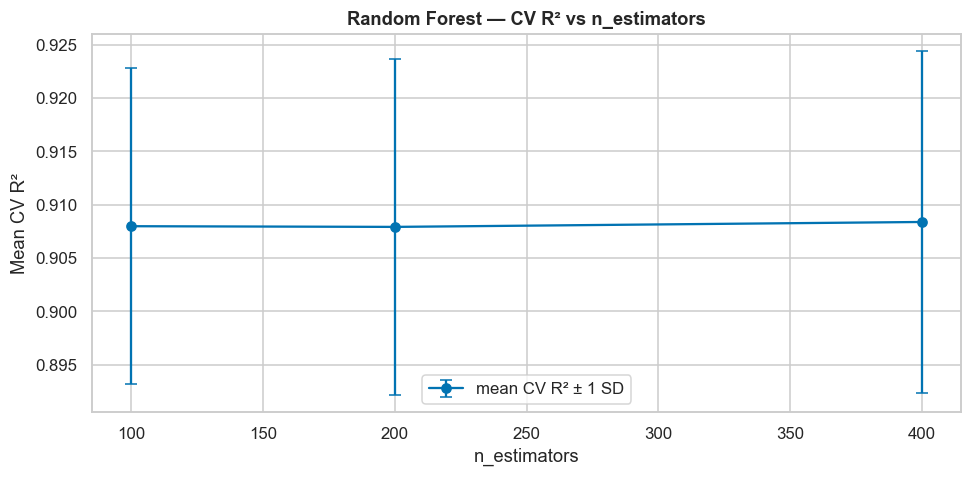

In [22]:
rf = run_model('Random Forest', RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
               {'n_estimators': [100, 200, 400], 'max_features': ['sqrt', 0.33, 1.0], 'max_depth': [None, 20]})
c = curve('Random Forest', 'n_estimators')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(c['n_estimators'].astype(int), c['mean_test_score'], yerr=c['std_test_score'], marker='o', capsize=4,
            color=PALETTE[0], label='mean CV R² ± 1 SD')
ax.set(title='Random Forest — CV R² vs n_estimators', xlabel='n_estimators', ylabel='Mean CV R²')
ax.legend()
plt.tight_layout(); save_fig(fig, 'random_forest'); plt.show()

### 4.8 Gradient Boosting Regressor — tune `learning_rate`

Gradient Boosting: 36 candidates in 168.4s → {'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 600, 'subsample': 0.8} (CV R² 0.9312)


,R2,RMSE,MAE
Stage,,,
Baseline,0.9221,"$19,766","$12,998"
Tuned,0.9298,"$18,769","$12,290"


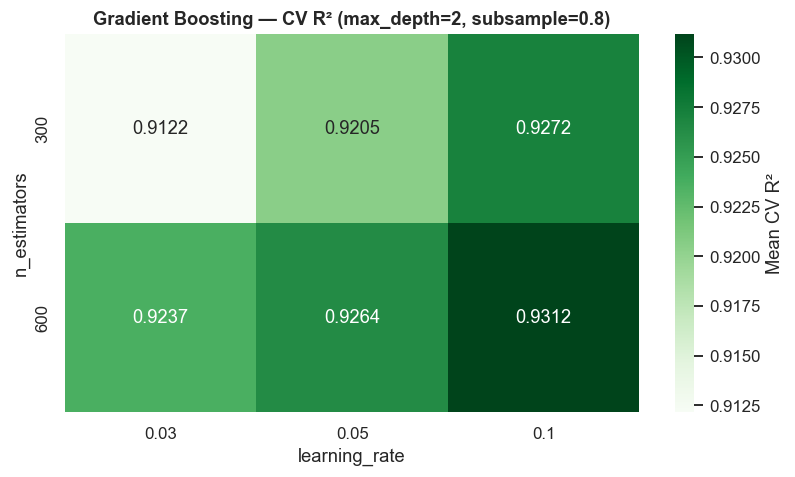

In [23]:
gb = run_model('Gradient Boosting', GradientBoostingRegressor(random_state=RANDOM_STATE),
               {'learning_rate': [0.03, 0.05, 0.1], 'n_estimators': [300, 600], 'max_depth': [2, 3, 4],
                'subsample': [0.8, 1.0]})
res = pd.DataFrame(SEARCHES['Gradient Boosting'].cv_results_)
bp = SEARCHES['Gradient Boosting'].best_params_
sub = res[(res['param_regressor__max_depth'] == bp['regressor__max_depth'])
          & (res['param_regressor__subsample'] == bp['regressor__subsample'])]
heat = sub.pivot_table(index='param_regressor__n_estimators', columns='param_regressor__learning_rate',
                       values='mean_test_score')
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.heatmap(heat, annot=True, fmt='.4f', cmap='Greens', cbar_kws={'label': 'Mean CV R²'}, ax=ax)
ax.set(title=f"Gradient Boosting — CV R² (max_depth={bp['regressor__max_depth']}, subsample={bp['regressor__subsample']})",
       xlabel='learning_rate', ylabel='n_estimators')
plt.tight_layout(); save_fig(fig, 'gradient_boosting_grid'); plt.show()

**📝 Observations — tree-based models**
- **Decision Tree:** the unpruned default tree scores R² 0.793. CV selects `max_depth = 10, min_samples_leaf = 10` (R² **0.843**, +0.050). A single tree is still the weakest model, because its step-function predictions cannot represent smooth price trends.
- **Random Forest:** `n_estimators = 400, max_features = 0.33, max_depth = 20` lifts R² from 0.912 to **0.922**. The CV curve shows only small differences between 100 and 400 trees (averaging has plateaued), while restricting each split to a third of the features de-correlates the trees.
- **Gradient Boosting:** the best setting uses **many shallow trees** (600 trees of depth 2, `learning_rate = 0.1`, `subsample = 0.8`): R² 0.922 → **0.930**. Shallow trees act like additive main effects, which suits this data.
- **Feature importance (C4):** in the tuned Gradient Boosting model, **`TotalSF` (0.34) and `Overall Qual` (0.27)** together account for over 60 % of the total importance, followed by `HouseAge`, `TotalBath` and `Kitchen Qual`. Three of the top four are **engineered features**, which directly validates the feature engineering of §3.2.

### 4.9 Support Vector Regressor — features scaled; tune `C` and `kernel`

Support Vector Regressor: 20 candidates in 24.6s → {'C': 0.01, 'epsilon': 0.05, 'kernel': 'linear'} (CV R² 0.9294)


,R2,RMSE,MAE
Stage,,,
Baseline,0.9097,"$21,289","$13,946"
Tuned,0.9315,"$18,533","$12,368"


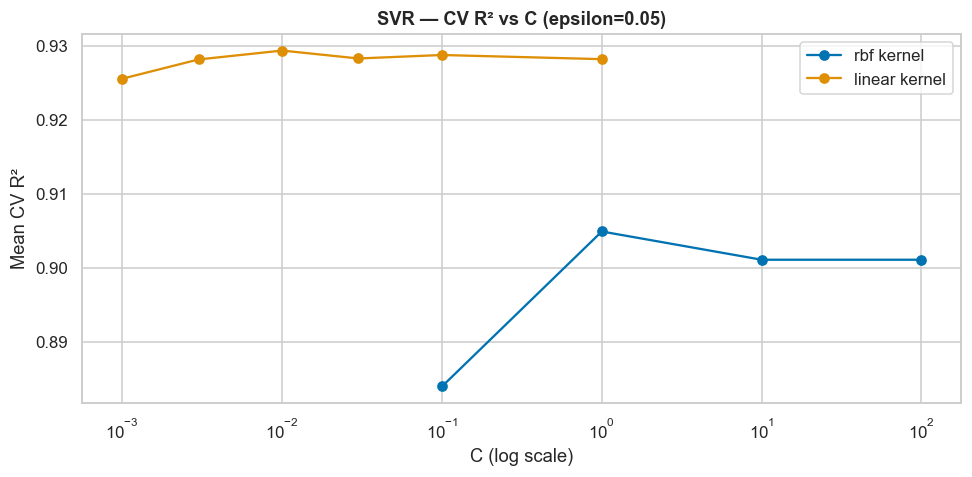

In [24]:
svr = run_model('Support Vector Regressor', SVR(),
                [{'kernel': ['rbf'], 'C': [0.1, 1, 10, 100], 'epsilon': [0.01, 0.05]},
                 {'kernel': ['linear'], 'C': [0.001, 0.003, 0.01, 0.03, 0.1, 1], 'epsilon': [0.01, 0.05]}])
res = pd.DataFrame(SEARCHES['Support Vector Regressor'].cv_results_)
best_eps = SEARCHES['Support Vector Regressor'].best_params_['regressor__epsilon']
sub = res[res['param_regressor__epsilon'] == best_eps]
fig, ax = plt.subplots(figsize=(9, 4.5))
for kern, color in zip(['rbf', 'linear'], PALETTE):
    s = sub[sub['param_regressor__kernel'] == kern].sort_values('param_regressor__C', key=lambda c: c.astype(float))
    ax.semilogx(s['param_regressor__C'].astype(float), s['mean_test_score'], marker='o', color=color, label=f'{kern} kernel')
ax.set(title=f'SVR — CV R² vs C (epsilon={best_eps})', xlabel='C (log scale)', ylabel='Mean CV R²')
ax.legend()
plt.tight_layout(); save_fig(fig, 'svr_grid'); plt.show()

**📝 Observations — Support Vector Regressor**
- In Review 1, SVR scored **R² = −0.04**: on the raw dollar target, the default `epsilon = 0.1` and `C` were meaningless (an error tube of 10 cents around prices of \$180,000). With the log target, a scaled feature matrix and tuning, SVR reaches **R² = 0.9315 (RMSE \$18,533)**, the best single test score.
- Even untuned, SVR now scores R² 0.910, which shows how much the target scale matters for this algorithm.
- The search selected a **linear kernel with small C = 0.01** (strong regularisation) and `epsilon = 0.05` (errors under ≈ 5 % are ignored). With 200 standardised, partly collinear features, a regularised linear fit in log space beats the flexible RBF kernel, which is consistent with Lasso/ElasticNet performing equally well.

### 4.10 K-Nearest Neighbours Regressor — tune `k`; impact of scaling

KNN Regressor: 60 candidates in 3.4s → {'n_neighbors': 5, 'p': 1, 'weights': 'distance'} (CV R² 0.8650)


,R2,RMSE,MAE
Stage,,,
Baseline,0.8760,"$24,941","$17,166"
Tuned,0.8893,"$23,568","$16,095"


,test R²
unscaled numeric + ordinal features,0.8118
standard-scaled (same features),0.8945


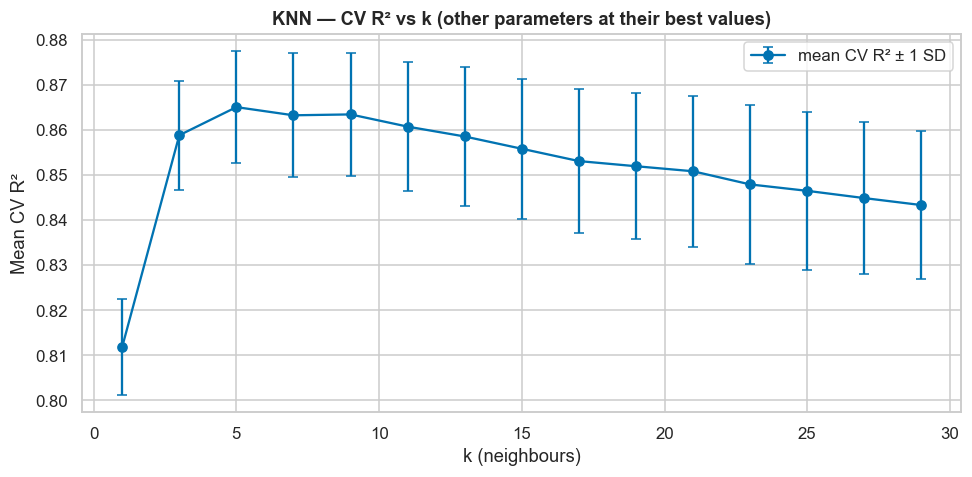

In [25]:
knn = run_model('KNN Regressor', KNeighborsRegressor(),
                {'n_neighbors': list(range(1, 31, 2)), 'weights': ['uniform', 'distance'], 'p': [1, 2]})
c = curve('KNN Regressor', 'n_neighbors')

# Impact of scaling: same tuned KNN on the UNSCALED (imputed + encoded) features
raw_prep = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUMERIC),
    ('ord', make_pipeline(SimpleImputer(strategy='constant', fill_value='None'),
                          OrdinalEncoder(categories=[ORDINAL_MAPS[c] for c in ORDINAL],
                                         handle_unknown='use_encoded_value', unknown_value=-1)), ORDINAL),
]).fit(X_train)
knn_unscaled = clone(knn).fit(raw_prep.transform(X_train), y_train)
knn_scaled_same = clone(knn).fit(X_train_p[NUMERIC + ORDINAL], y_train)
scaling = pd.DataFrame({
    'test R²': [r2_score(y_test, knn_unscaled.predict(raw_prep.transform(X_test))),
                r2_score(y_test, knn_scaled_same.predict(X_test_p[NUMERIC + ORDINAL]))]},
    index=['unscaled numeric + ordinal features', 'standard-scaled (same features)'])
display(scaling.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.errorbar(c['n_neighbors'].astype(int), c['mean_test_score'], yerr=c['std_test_score'], marker='o', capsize=3,
            color=PALETTE[0], label='mean CV R² ± 1 SD')
ax.set(title='KNN — CV R² vs k (other parameters at their best values)', xlabel='k (neighbours)', ylabel='Mean CV R²')
ax.legend()
plt.tight_layout(); save_fig(fig, 'knn_curve'); plt.show()

**📝 Observations — KNN Regressor**
- CV selected **k = 5 with distance weighting and Manhattan distance (p = 1)**: R² 0.876 → **0.889**. Manhattan distance is less dominated by a single large coordinate difference than Euclidean distance.
- **Impact of scaling:** with the same tuned settings on the same numeric + ordinal features, R² is **0.812 unscaled vs 0.895 scaled**. Without scaling, `Lot Area` (thousands of sq ft) dominates every distance and swamps 1–10 quality ratings.
- KNN still trails the linear and ensemble models: with about 200 dimensions, the "nearest" houses are not very similar (curse of dimensionality).

---
## 5 · Comparative evaluation — all 10 models on the same test split (ranked by R²)

,Model,R2,RMSE,MAE
Rank,,,,
1,Support Vector Regressor,0.9315,"$18,533","$12,368"
2,ElasticNet,0.9313,"$18,568","$12,660"
3,Lasso Regression,0.9313,"$18,572","$12,668"
4,Gradient Boosting,0.9298,"$18,769","$12,290"
5,Ridge Regression,0.9275,"$19,075","$12,730"
6,Linear Regression,0.9234,"$19,610","$12,909"
7,Random Forest,0.9215,"$19,849","$12,916"
8,KNN Regressor,0.8893,"$23,568","$16,095"
9,Polynomial Regression,0.8732,"$25,227","$17,634"


,R2 baseline,R2,Δ R2,RMSE baseline,RMSE,Δ RMSE,Best parameters
Model,,,,,,,
Support Vector Regressor,0.9097,0.9315,+0.0219,"$21,289","$18,533","-2,756","{'C': 0.01, 'epsilon': 0.05, 'kernel': 'linear'}"
ElasticNet,-0.0415,0.9313,+0.9728,"$72,291","$18,568","-53,724","{'alpha': 0.001, 'l1_ratio': 0.3}"
Lasso Regression,-0.0415,0.9313,+0.9728,"$72,291","$18,572","-53,719",{'alpha': 0.0003162}
Gradient Boosting,0.9221,0.9298,+0.0077,"$19,766","$18,769",-998,"{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 600, 'subsample': 0.8}"
Ridge Regression,0.9228,0.9275,+0.0047,"$19,677","$19,075",-602,{'alpha': 31.62}
Linear Regression,0.9234,0.9234,+0.0000,"$19,610","$19,610",+0,— (no hyper-parameters)
Random Forest,0.9120,0.9215,+0.0094,"$21,008","$19,849","-1,158","{'max_depth': 20, 'max_features': 0.33, 'n_estimators': 400}"
KNN Regressor,0.8760,0.8893,+0.0133,"$24,941","$23,568","-1,373","{'n_neighbors': 5, 'p': 1, 'weights': 'distance'}"
Polynomial Regression,0.8732,0.8732,+0.0000,"$25,227","$25,227",+0,{'degree': 1}


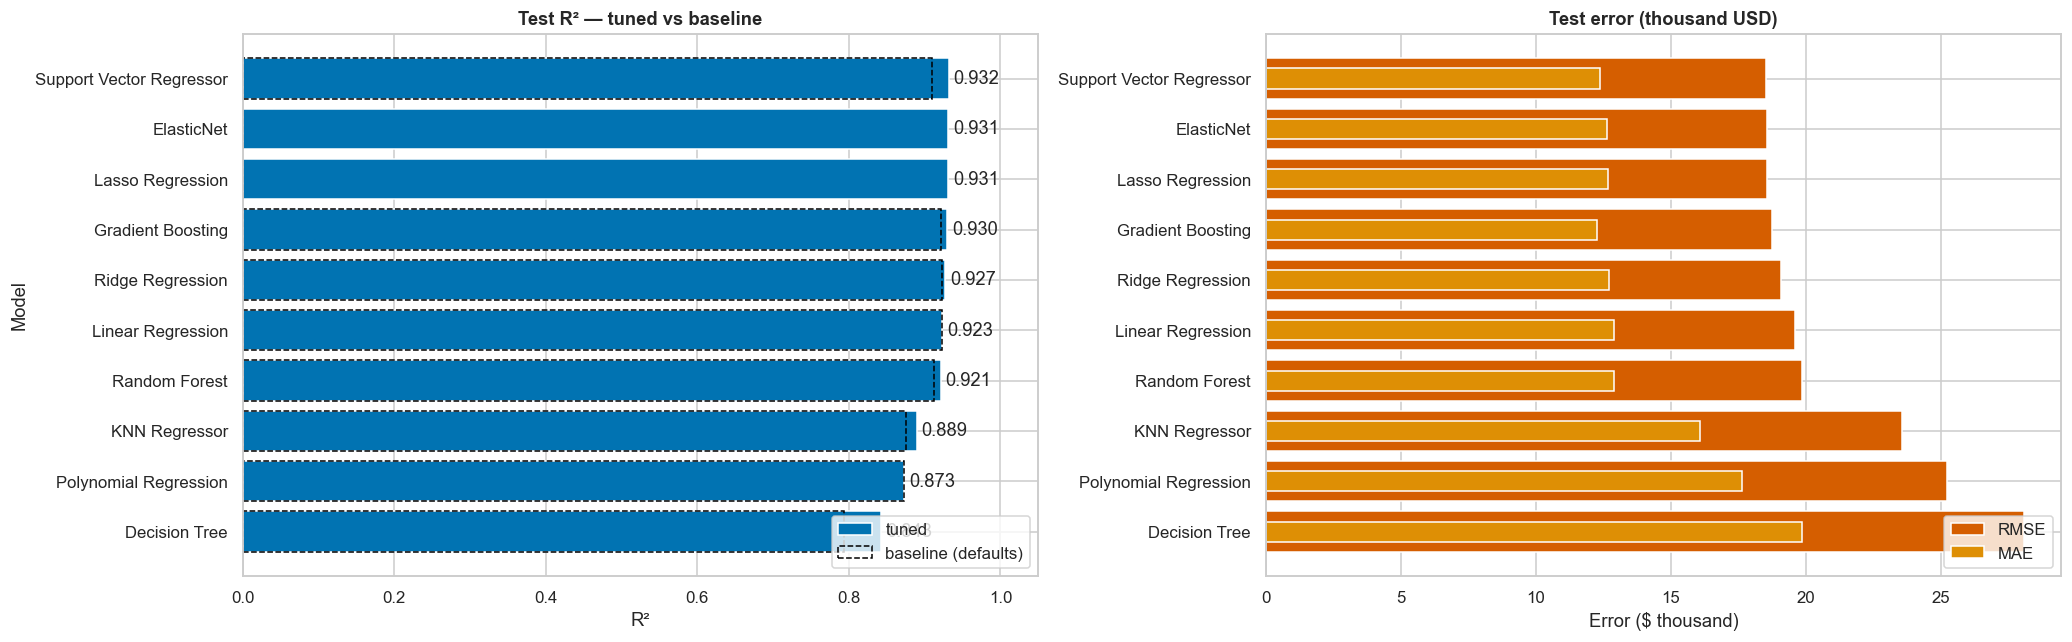

In [26]:
def table(stage):
    t = pd.DataFrame([{k: v for k, v in r.items() if k not in ('model', 'y_pred', 'Stage')}
                      for (n, s), r in RESULTS.items() if s == stage])
    t = t.sort_values('R2', ascending=False).reset_index(drop=True)
    t.index = t.index + 1; t.index.name = 'Rank'
    return t


final_table = table('Tuned')
display(final_table.style.format({'R2': '{:.4f}', 'RMSE': '${:,.0f}', 'MAE': '${:,.0f}'})
        .background_gradient(subset=['R2'], cmap='Greens')
        .background_gradient(subset=['RMSE', 'MAE'], cmap='Reds')
        .set_caption('All 10 regressors (tuned) — test split, ranked by R²'))
final_table.to_csv(REPORTS_DIR / 'regression_comparison.csv', index_label='Rank', float_format='%.4f')

base_t = table('Baseline').set_index('Model')
gain = final_table.set_index('Model')[['R2', 'RMSE']].join(base_t[['R2', 'RMSE']], rsuffix=' baseline')
gain['Δ R2'] = gain['R2'] - gain['R2 baseline']
gain['Δ RMSE'] = gain['RMSE'] - gain['RMSE baseline']
gain['Best parameters'] = pd.Series({n: str(fmt_params(s.best_params_, 'regressor__')) for n, s in SEARCHES.items()})
gain.loc['Polynomial Regression', 'Best parameters'] = f"{{'degree': {BEST_DEG}}}"
gain = gain[['R2 baseline', 'R2', 'Δ R2', 'RMSE baseline', 'RMSE', 'Δ RMSE', 'Best parameters']].fillna({'Best parameters': '— (no hyper-parameters)'})
display(gain.style.format({'R2 baseline': '{:.4f}', 'R2': '{:.4f}', 'Δ R2': '{:+.4f}', 'RMSE baseline': '${:,.0f}',
                           'RMSE': '${:,.0f}', 'Δ RMSE': '{:+,.0f}'})
        .set_caption('Effect of hyper-parameter tuning (baseline = library defaults)'))
gain.to_csv(REPORTS_DIR / 'regression_tuning_gains.csv', float_format='%.4f')

fig, axes = plt.subplots(1, 2, figsize=(19, 6))
p = final_table.sort_values('R2')
axes[0].barh(p['Model'], p['R2'], color=PALETTE[0], label='tuned')
axes[0].barh(p['Model'], base_t.loc[p['Model'], 'R2'].clip(lower=0), color='none', edgecolor='black', ls='--',
             label='baseline (defaults)')
axes[0].bar_label(axes[0].containers[0], fmt='%.3f', padding=3)
axes[0].set(title='Test R² — tuned vs baseline', xlabel='R²', ylabel='Model', xlim=(0, 1.05))
axes[0].legend(loc='lower right')
axes[1].barh(p['Model'], p['RMSE'] / 1e3, color=PALETTE[3], label='RMSE')
axes[1].barh(p['Model'], p['MAE'] / 1e3, color=PALETTE[1], height=0.4, label='MAE')
axes[1].set(title='Test error (thousand USD)', xlabel='Error ($ thousand)', ylabel='')
axes[1].legend(loc='lower right')
plt.tight_layout(); save_fig(fig, 'model_comparison'); plt.show()

**📝 Observations — comparison of all 10 models**
- **Top tier (R² ≈ 0.93, RMSE ≈ \$18.6k):** SVR (0.9315), ElasticNet and Lasso (both 0.9313) are virtually tied, with Gradient Boosting just behind (0.9298) and Ridge (0.9275). After the log transform and proper encoding, the price is close to **linear in log space**, so well-regularised linear models match the best boosting ensemble.
- **Middle tier:** OLS (0.923) and Random Forest (0.922).
- **Lower tier:** KNN (0.889), Polynomial on 10 features (0.873) and the single Decision Tree (0.843).
- **Tuning effect (C3):** tuning improved 8 of 10 models. The gains are huge for Lasso/ElasticNet (+0.97 R², from a constant predictor to a top model) and clear for the Decision Tree (+0.050), SVR (+0.022), KNN (+0.013), Random Forest (+0.009) and Gradient Boosting (+0.008).
- Compared with Review 1 (best R² 0.924, Gradient Boosting), the revised pipeline improves the best test R² to **0.931** and **RMSE from \$19,510 to \$18,568**.

---
## 6 · 5-fold cross-validation of the two best models

The complete pipeline (preprocessing + log-target model) is re-fitted inside each fold on the **training split**, so
no fold ever sees statistics from its validation part.

,CV R² mean,CV R² std,CV RMSE mean,CV MAE mean,fold R²
Model,,,,,
Support Vector Regressor,0.9289,0.0125,"$19,029","$12,670","[0.9255, 0.9211, 0.952, 0.9302, 0.9157]"
ElasticNet,0.9311,0.0104,"$18,749","$12,858","[0.9253, 0.9186, 0.9496, 0.9295, 0.9323]"


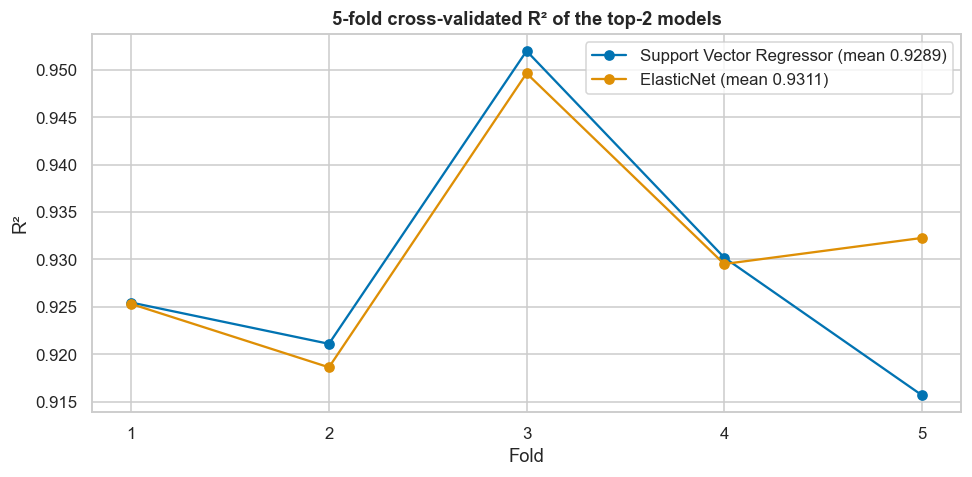

Best model (highest mean CV R²): ElasticNet — test R² 0.9313, RMSE $18,568


In [27]:
top2 = final_table['Model'].head(2).tolist()
cv_rows, cv_raw = [], {}
for name in top2:
    reg = RESULTS[(name, 'Tuned')]['model']
    pipe = Pipeline([('prep', build_preprocessor()), ('model', clone(reg))])
    cv = cross_validate(pipe, X_train, y_train, cv=CV5, n_jobs=-1,
                        scoring={'R2': 'r2', 'RMSE': 'neg_root_mean_squared_error', 'MAE': 'neg_mean_absolute_error'})
    cv_raw[name] = cv['test_R2']
    cv_rows.append({'Model': name, 'CV R² mean': cv['test_R2'].mean(), 'CV R² std': cv['test_R2'].std(),
                    'CV RMSE mean': -cv['test_RMSE'].mean(), 'CV MAE mean': -cv['test_MAE'].mean(),
                    'fold R²': np.round(cv['test_R2'], 4).tolist()})
cv_table = pd.DataFrame(cv_rows).set_index('Model')
display(cv_table.style.format({'CV R² mean': '{:.4f}', 'CV R² std': '{:.4f}', 'CV RMSE mean': '${:,.0f}',
                               'CV MAE mean': '${:,.0f}'}))

fig, ax = plt.subplots(figsize=(9, 4.5))
for i, (name, scores) in enumerate(cv_raw.items()):
    ax.plot(range(1, 6), scores, marker='o', color=PALETTE[i], label=f'{name} (mean {scores.mean():.4f})')
ax.set(title='5-fold cross-validated R² of the top-2 models', xlabel='Fold', ylabel='R²', xticks=range(1, 6))
ax.legend()
plt.tight_layout(); save_fig(fig, 'cv_top2'); plt.show()

BEST_NAME = cv_table['CV R² mean'].idxmax()
best = RESULTS[(BEST_NAME, 'Tuned')]
print(f'Best model (highest mean CV R²): {BEST_NAME} — test R² {best["R2"]:.4f}, RMSE ${best["RMSE"]:,.0f}')

**📝 Observations — cross-validation of the top-2**
- Both models are very stable: ElasticNet **CV R² 0.9311 ± 0.0104** and SVR 0.9289 ± 0.0125, with every fold between 0.916 and 0.952.
- The test R² (0.9313) sits right in the middle of the CV range, so the test split is representative and neither model over-fits it.
- **ElasticNet is selected as the final model.** SVR is 0.0002 ahead on the single test split, a negligible difference, but ElasticNet has the higher cross-validated R², lower CV RMSE (\$18,749 vs \$19,029) and lower fold-to-fold variance. It is also simpler and faster than SVR, and its coefficients remain interpretable.

---
## 7 · Diagnostic plots for the best model

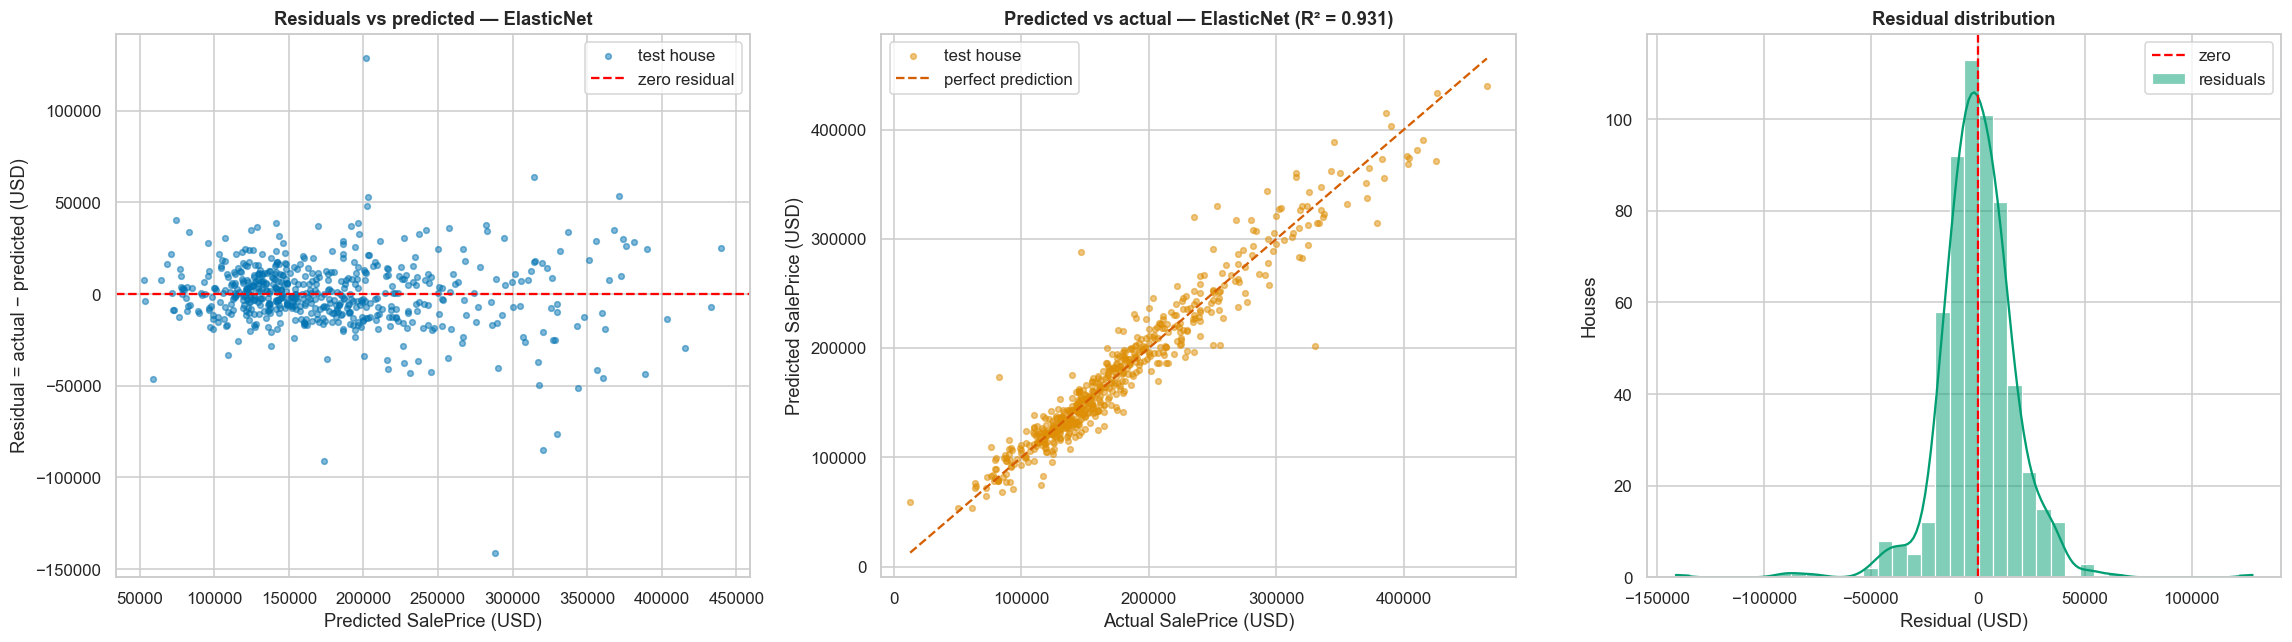

Median absolute percentage error: 5.6% | 90% of houses within ±15.0%


In [28]:
pred = best['y_pred']
resid = y_test.values - pred
fig, axes = plt.subplots(1, 3, figsize=(21, 6))
axes[0].scatter(pred, resid, s=14, alpha=0.5, color=PALETTE[0], label='test house')
axes[0].axhline(0, color='red', ls='--', label='zero residual')
axes[0].set(title=f'Residuals vs predicted — {BEST_NAME}', xlabel='Predicted SalePrice (USD)',
            ylabel='Residual = actual − predicted (USD)')
axes[0].legend()
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
axes[1].scatter(y_test, pred, s=14, alpha=0.5, color=PALETTE[1], label='test house')
axes[1].plot(lims, lims, 'r--', label='perfect prediction')
axes[1].set(title=f'Predicted vs actual — {BEST_NAME} (R² = {best["R2"]:.3f})', xlabel='Actual SalePrice (USD)',
            ylabel='Predicted SalePrice (USD)')
axes[1].legend()
sns.histplot(resid, bins=40, kde=True, ax=axes[2], color=PALETTE[2], label='residuals')
axes[2].axvline(0, color='red', ls='--', label='zero')
axes[2].set(title='Residual distribution', xlabel='Residual (USD)', ylabel='Houses')
axes[2].legend()
plt.tight_layout(); save_fig(fig, 'residual_diagnostics'); plt.show()
pct = np.abs(resid) / y_test.values * 100
print(f'Median absolute percentage error: {np.median(pct):.1f}% | 90% of houses within ±{np.percentile(pct, 90):.1f}%')

**📝 Observations — residual diagnostics (ElasticNet)**
- **Residuals vs predicted:** the points are centred on zero with no curve, so the model has captured the main (log-linear) structure. The spread widens slightly for expensive houses (heteroscedasticity). This is expected because errors are proportional to price on the log scale.
- **Predicted vs actual:** the points lie tightly along the 45° line across the whole range. A handful of houses are mis-priced by more than \$75k. They are unusual properties or sale conditions that the recorded features cannot fully describe.
- **Residual distribution:** roughly symmetric and centred on 0. The **median absolute percentage error is 5.6 %**, and **90 % of test houses are predicted within ±15 %** of their sale price.

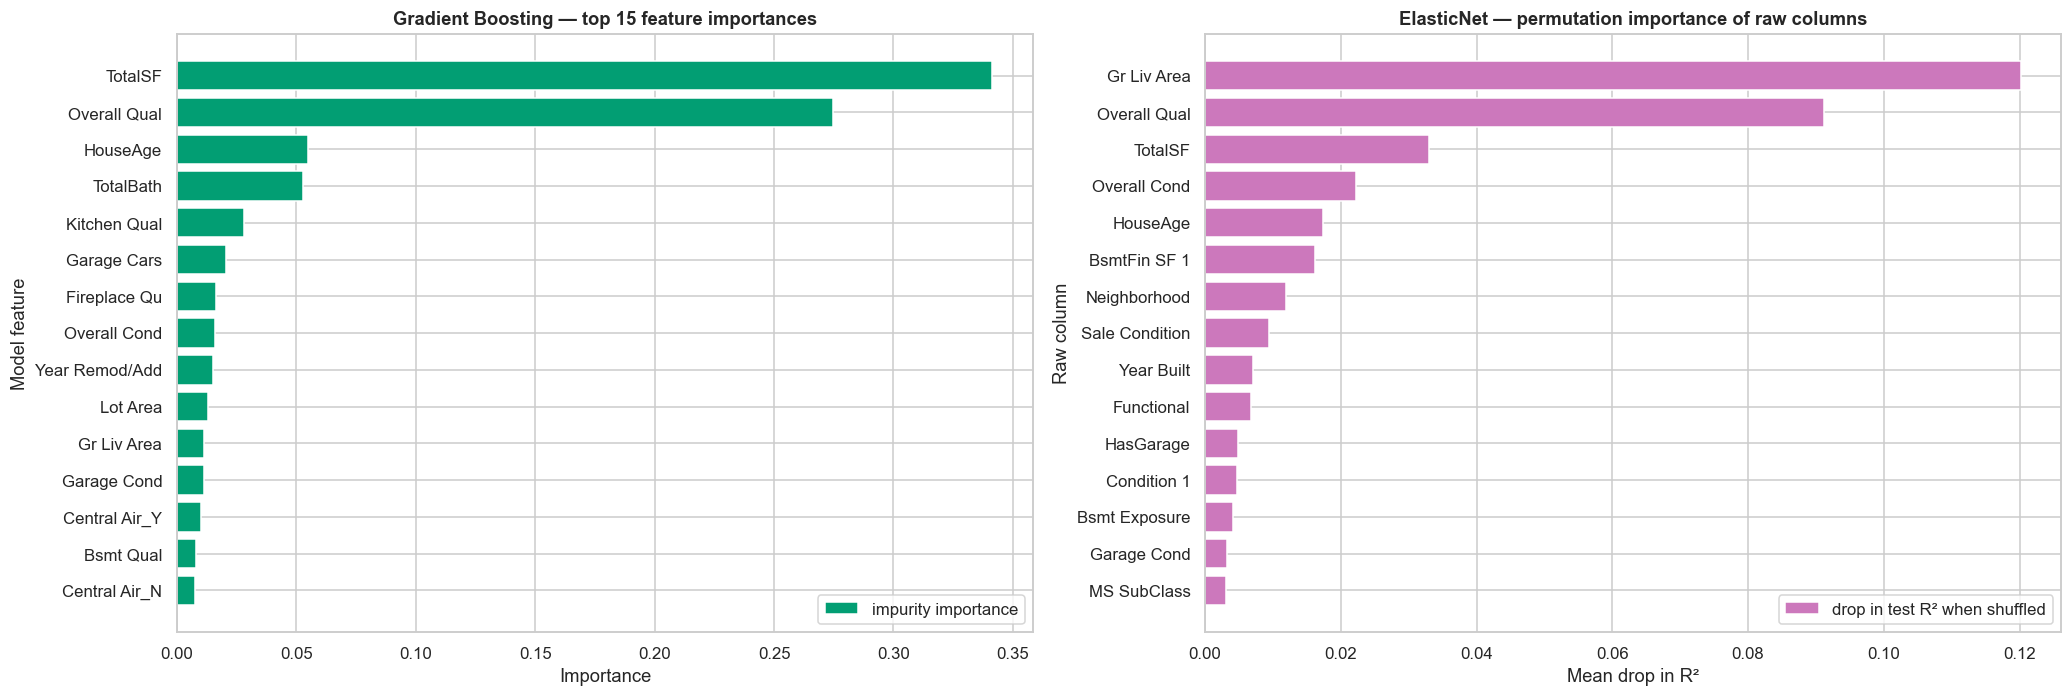

In [29]:
gbm = RESULTS[('Gradient Boosting', 'Tuned')]['model'].regressor_
imp = pd.Series(gbm.feature_importances_, index=X_train_p.columns).sort_values().tail(15)
final_pipe = Pipeline([('prep', preprocessor), ('model', best['model'])])
perm = permutation_importance(final_pipe, X_test, y_test, scoring='r2', n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_test.columns).sort_values().tail(15)

fig, axes = plt.subplots(1, 2, figsize=(19, 6.5))
axes[0].barh(imp.index, imp.values, color=PALETTE[2], label='impurity importance')
axes[0].set(title='Gradient Boosting — top 15 feature importances', xlabel='Importance', ylabel='Model feature')
axes[0].legend(loc='lower right')
axes[1].barh(perm_s.index, perm_s.values, color=PALETTE[4], label='drop in test R² when shuffled')
axes[1].set(title=f'{BEST_NAME} — permutation importance of raw columns', xlabel='Mean drop in R²', ylabel='Raw column')
axes[1].legend(loc='lower right')
plt.tight_layout(); save_fig(fig, 'feature_importance'); plt.show()

**📝 Observations — feature importance**
- **Gradient Boosting (impurity importance):** `TotalSF` and `Overall Qual` dominate, followed by `HouseAge`, `TotalBath`, `Kitchen Qual` and `Garage Cars`.
- **ElasticNet (permutation importance on raw columns, test split):** shuffling `Gr Liv Area` lowers test R² by about 0.12 and `Overall Qual` by about 0.09, followed by `TotalSF`, `Overall Cond`, `HouseAge`, `BsmtFin SF 1` and `Neighborhood`.
- Both views agree on the story: **size, quality, age and location** drive price. Engineered features (`TotalSF`, `HouseAge`, `HasGarage`) rank high in both models.

---
## 8 · Saving the model and results

The saved pipeline takes **raw Ames columns plus the six engineered features** and returns a price in USD.

In [30]:
final_pipeline = Pipeline([('preprocessor', preprocessor), ('model', best['model'])])
assert np.allclose(final_pipeline.predict(X_test), best['y_pred'])
joblib.dump(final_pipeline, MODELS_DIR / 'regression_best_model.pkl')

defaults = {c: (float(X_train[c].median()) if c in NUMERIC else
                (X_train[c].mode().iat[0] if X_train[c].notna().any() else None)) for c in X_train.columns}
summary = {
    'track': 'regression', 'dataset': 'Ames Housing', 'n_rows_after_cleaning': int(len(data)),
    'n_train': int(len(X_train)), 'n_test': int(len(X_test)), 'target_transform': 'log1p / expm1',
    'median_price': float(y.median()),
    'best_model': BEST_NAME,
    'best_params': (fmt_params(SEARCHES[BEST_NAME].best_params_, 'regressor__')),
    'test_metrics': {k: round(float(best[k]), 4) for k in ['R2', 'RMSE', 'MAE']},
    'cv_top2': {n: {k: (round(float(v), 4) if not isinstance(v, list) else v) for k, v in r.items()}
                for n, r in cv_table.to_dict('index').items()},
    'comparison': final_table.round(4).to_dict('records'),
    'tuning_gains': gain.reset_index().round(4).to_dict('records'),
    'feature_defaults': {k: (v.item() if hasattr(v, 'item') else v) for k, v in defaults.items()},
    'neighborhoods': sorted(X_train['Neighborhood'].unique().tolist()),
    'random_state': RANDOM_STATE,
}
(REPORTS_DIR / 'regression_results.json').write_text(json.dumps(summary, indent=2, default=str))

# All 10 tuned models as raw-input pipelines — used by the GUI's model lab and live evaluation
poly_select = ColumnTransformer([('keep', 'passthrough', POLY_FEATS)],
                                verbose_feature_names_out=False).set_output(transform='pandas').fit(X_train_p)
all_models = {}
for name in final_table['Model']:
    steps = [('preprocessor', preprocessor)]
    if name == 'Polynomial Regression':
        steps.append(('select_top10', poly_select))
    all_models[name] = Pipeline(steps + [('model', RESULTS[(name, 'Tuned')]['model'])])
    assert np.allclose(all_models[name].predict(X_test), RESULTS[(name, 'Tuned')]['y_pred'])
joblib.dump(all_models, MODELS_DIR / 'regression_all_models.pkl', compress=3)
print(f'All 10 tuned pipelines: models/regression_all_models.pkl '
      f'({(MODELS_DIR / "regression_all_models.pkl").stat().st_size / 1e6:.1f} MB)')
print('Saved models/regression_best_model.pkl and reports/regression_results.json')
print(f'Reloaded model test R² = {r2_score(y_test, joblib.load(MODELS_DIR / "regression_best_model.pkl").predict(X_test)):.4f}')

All 10 tuned pipelines: models/regression_all_models.pkl (21.3 MB)
Saved models/regression_best_model.pkl and reports/regression_results.json
Reloaded model test R² = 0.9313


---
## 9 · Conclusions

**Final model:** **ElasticNet** (`alpha = 0.001`, `l1_ratio = 0.3`) on log-price. Test **R² = 0.931, RMSE = \$18,568, MAE = \$12,660**; 5-fold CV R² **0.931 ± 0.010**. Median absolute error is 5.6 % of the sale price.

**Key findings**
1. **Treat the target properly.** Modelling `log(SalePrice)` turned SVR from the worst model (R² −0.04) into the best on the test split (0.9315), and lifted every linear model.
2. **Engineered features matter.** `TotalSF` is the most correlated feature (r = 0.82) and the top Gradient Boosting feature. Three of the top four tree features are engineered.
3. **Regularisation must be tuned.** The default Lasso/ElasticNet predict a constant. Tuned, they are the best models and Lasso keeps only 124 of 202 features.
4. **Simple can win.** In log space the price is close to additive, so regularised linear models match Gradient Boosting (0.931 vs 0.930) while being faster and interpretable.
5. **Complexity control:** polynomial degree 3 and the unpruned tree show over-fitting clearly. Cross-validation, never the test set, picked every hyper-parameter.

**References:** De Cock, D. (2011). *Ames, Iowa: Alternative to the Boston Housing Data as an End of Semester Regression Project.* Journal of Statistics Education 19(3) · scikit-learn 1.8 user guide (linear models, ensembles, `TransformedTargetRegressor`).